# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 1: Exploratory Data Analysis (EDA) & Data Preparation

| | |
|---|---|
| **Student name** | Dinh Phu Nguyen |
| **Student ID** | 105027282 |
| **Date** | 4 Oct 2026 |
| **Dataset** | Appliances Energy Prediction — Candanedo, L. (2017), UCI Machine Learning Repository, DOI: [10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G) |

## Generative AI Use Declaration

"I used Claude (Anthropic) to assist with suggesting a suitable dataset, structuring and  debugging my Python environment. All final code, interpretations, and conclusions are my own work after verification."

*Evidence of the GenAI use is provided in Appendix A of the PDF report.*

## Contents
0. Setup
1. Task 1 – Dataset Loading & Initial Exploration
2. Task 2 – Data Quality Assessment
3. Task 3 – Target Variable Preparation
4. Task 4 – Univariate Analysis
5. Task 5 – Multivariate Analysis
6. Initial Insights for Modelling
7. Task 6 – Engineering Interpretation
8. Task 7 – Challenges Encountered
9. Task 8 – Responsible AI Reflection
10. Task 9 – Summary Report

## 0. Setup
Imports, global settings and a helper for saving figures. Running this cell first makes every later cell reproducible.

In [1]:
# --- Imports ---
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Reproducibility & file paths ---
RANDOM_STATE = 42                                    # fixed seed for any sampling (e.g. pairplot subsample)
DATA_PATH = Path("data") / "energydata_complete.csv"  # relative path, so the repo runs on any machine
FIG_DIR = Path("figures")                            # all figures are saved here for the PDF report
FIG_DIR.mkdir(exist_ok=True)

# --- Display & plotting defaults (one consistent style for every figure) ---
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,       # on-screen size
    "savefig.dpi": 300,      # print quality for the PDF report
    "savefig.bbox": "tight",
})

# Fixed colours so every figure in the report looks consistent
COLOR_MAIN = "#2a78d6"     # first data series (blue)
COLOR_SECOND = "#eb6834"   # second data series (orange)
COLOR_MISSING = "#e34948"  # highlights missing / invalid values (red)
COLOR_TEXT = "#52514e"     # annotations and secondary text (grey)


def save_fig(fig, name):
    """Save a matplotlib figure to figures/<name>.png at print resolution and return the path."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    return path


# --- Environment info (lets a marker reproduce the exact results) ---
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Task 1 – Dataset Loading & Initial Exploration

**About the dataset.** Energy use of household appliances in a low-energy house in Belgium, logged every 10 minutes for about 4.5 months. Indoor temperature and humidity come from a wireless (ZigBee) sensor network, and outdoor weather comes from the nearest airport weather station (Chièvres). Licence: CC BY 4.0.

Reference: Candanedo, L., Feldheim, V., & Deramaix, D. (2017). *Data driven prediction models of energy use of appliances in a low-energy house.* Energy and Buildings, 140.

### 1.0 Variable dictionary
Descriptions and units from the UCI documentation. The `UNITS` mapping is reused later to put units on plot axes.

In [2]:
# Variable dictionary from the UCI documentation: column -> (description, unit)
ROOMS = {1: "kitchen", 2: "living room", 3: "laundry room", 4: "office", 5: "bathroom",
         6: "outside, north side of building", 7: "ironing room", 8: "teenager room 2", 9: "parents room"}

VARIABLES = {
    "date": ("Timestamp of the 10-minute reading", "-"),
    "Appliances": ("Energy use of appliances (TARGET)", "Wh"),
    "lights": ("Energy use of light fixtures", "Wh"),
}
for i, room in ROOMS.items():
    VARIABLES[f"T{i}"] = (f"Temperature – {room}", "°C")
    VARIABLES[f"RH_{i}"] = (f"Relative humidity – {room}", "%")
VARIABLES.update({
    "T_out": ("Outdoor temperature (Chièvres weather station)", "°C"),
    "Press_mm_hg": ("Atmospheric pressure (weather station)", "mm Hg"),
    "RH_out": ("Outdoor relative humidity (weather station)", "%"),
    "Windspeed": ("Wind speed (weather station)", "m/s"),
    "Visibility": ("Visibility (weather station)", "km"),
    "Tdewpoint": ("Dew point temperature (weather station)", "°C"),
    "rv1": ("Random variable 1, added by the dataset authors", "nondimensional"),
    "rv2": ("Random variable 2, added by the dataset authors", "nondimensional"),
})

UNITS = {col: unit for col, (_, unit) in VARIABLES.items()}  # used for axis labels in later plots

data_dictionary = pd.DataFrame(VARIABLES, index=["description", "unit"]).T
data_dictionary.index.name = "column"
display(data_dictionary)

,description,unit
column,,
date,Timestamp of the 10-minute reading,-
Appliances,Energy use of appliances (TARGET),Wh
lights,Energy use of light fixtures,Wh
T1,Temperature – kitchen,°C
RH_1,Relative humidity – kitchen,%
T2,Temperature – living room,°C
RH_2,Relative humidity – living room,%
T3,Temperature – laundry room,°C
RH_3,Relative humidity – laundry room,%


### 1.1 Load the data
The raw CSV is loaded as published, with no type conversion. Type fixes are made and documented in Task 2.

In [3]:
# Fail early with a clear message if the data file is not where the notebook expects it
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} not found. Download energydata_complete.csv (see README.md) into the data/ folder."
    )

df_raw = pd.read_csv(DATA_PATH)  # untouched copy of the published data, kept for reference
df = df_raw.copy()               # working copy that later tasks will clean and extend

print(f"Loaded '{DATA_PATH}'")

Loaded 'data/energydata_complete.csv'


### 1.2 Dataset shape

In [4]:
n_rows, n_cols = df.shape
print(f"Shape: {df.shape} -> {n_rows:,} rows x {n_cols} columns")

# Each row is one 10-minute reading, so the row count should match the time span covered
timestamps = pd.to_datetime(df["date"])
print(f"Time span: {timestamps.min()} to {timestamps.max()} "
      f"({(timestamps.max() - timestamps.min()).days} days)")

Shape: (19735, 29) -> 19,735 rows x 29 columns
Time span: 2016-01-11 17:00:00 to 2016-05-27 18:00:00 (137 days)


### 1.3 First 5 rows

In [5]:
display(df.head())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


### 1.4 Data types of all columns
`n_unique` is shown next to each type because a numeric column with very few distinct values may behave like a categorical one.

In [6]:
dtype_table = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
})
display(dtype_table)

print("Column count by data type:")
print(df.dtypes.astype(str).value_counts().to_string())

,dtype,non_null,n_unique
date,str,19735,19735
Appliances,int64,19735,92
lights,int64,19735,8
T1,float64,19735,722
RH_1,float64,19735,2547
T2,float64,19735,1650
RH_2,float64,19735,3376
T3,float64,19735,1426
RH_3,float64,19735,2618
T4,float64,19735,1390


Column count by data type:
float64    26
int64       2
str         1


### 1.5 Basic statistical summary

In [7]:
# Transposed so each variable is a row: easier to read with 28 numeric columns
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.69,102.52,10.00,50.00,60.00,100.00,1080.00
lights,19735.0,3.80,7.94,0.00,0.00,0.00,0.00,70.00
T1,19735.0,21.69,1.61,16.79,20.76,21.60,22.60,26.26
RH_1,19735.0,40.26,3.98,27.02,37.33,39.66,43.07,63.36
T2,19735.0,20.34,2.19,16.10,18.79,20.00,21.50,29.86
RH_2,19735.0,40.42,4.07,20.46,37.90,40.50,43.26,56.03
T3,19735.0,22.27,2.01,17.20,20.79,22.10,23.29,29.24
RH_3,19735.0,39.24,3.25,28.77,36.90,38.53,41.76,50.16
T4,19735.0,20.86,2.04,15.10,19.53,20.67,22.10,26.20
RH_4,19735.0,39.03,4.34,27.66,35.53,38.40,42.16,51.09


### 1.6 Initial missing value check
Two checks: empty cells, and missing time steps. In a time series, a reading that was never recorded leaves no empty cell, so it only shows up as a gap in the timestamps.

In [8]:
# (a) Empty cells per column
missing_cells = df.isnull().sum()
print(f"Total missing cells: {missing_cells.sum()}")
if missing_cells.any():
    display(missing_cells[missing_cells > 0].to_frame("missing_count"))
else:
    print("No column contains missing cells.")

# (b) Missing 10-minute time steps between the first and last reading
expected_steps = pd.date_range(timestamps.min(), timestamps.max(), freq="10min")
missing_steps = expected_steps.difference(timestamps)
print(f"\nExpected 10-minute steps: {len(expected_steps):,} | "
      f"Unique timestamps present: {timestamps.nunique():,} | Missing steps: {len(missing_steps)}")

Total missing cells: 0
No column contains missing cells.

Expected 10-minute steps: 19,735 | Unique timestamps present: 19,735 | Missing steps: 0


### 1.7 Task 1 observations

- **Shape and sampling:** 19,735 rows × 29 columns. Each row is one 10-minute reading from 11 January to 27 May 2016 (137 days), and all 19,735 expected timestamps are present, so the time series is complete and regular.
- **Data types:** 26 float64 sensor columns, 2 int64 columns (`Appliances`, `lights`) and 1 text column (`date`). The timestamp is stored as text and must be converted to datetime (Task 2) before time-based analysis.
- **Target:** `Appliances` has a mean of 97.7 Wh but a median of only 60 Wh and a maximum of 1,080 Wh, so it is strongly right-skewed, with occasional large peaks. It takes only 92 distinct values because the meter records 10 Wh steps.
- **Few distinct values:** `lights` has only 8 distinct values (0–70 Wh in 10 Wh steps) and its 75th percentile is 0, so most readings are 0.
- **Early warning signs for Task 2:** `rv1` and `rv2` have identical statistics (possible duplicate columns), and the outdoor wall sensor `RH_6` spans 1–99.9%, much wider than the weather station's `RH_out` (24–100%), which needs checking.
- **Missing values:** none in any column, and no missing time steps.

## 2. Task 2 – Data Quality Assessment
Four checks: missing values, duplicates, outliers (statistical **and** physical), then the cleaning decisions. The raw data in `df` is not modified until section 2.5, so every check describes the data exactly as published.

### 2.1 Missing values table with percentages

In [9]:
# Missing count and percentage for EVERY column (columns with 0% are kept to show they were checked)
missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing_table)

n_missing_cells = int(df.isnull().sum().sum())
print(f"Columns with at least one missing value: {(missing_table['missing_count'] > 0).sum()} of {df.shape[1]}")
print(f"Missing cells overall: {n_missing_cells} of {df.size:,} ({n_missing_cells / df.size * 100:.2f}%)")
print(f"Missing 10-minute time steps (from Task 1.6): {len(missing_steps)}")

,missing_count,missing_pct
date,0,0.0
Appliances,0,0.0
lights,0,0.0
T1,0,0.0
RH_1,0,0.0
T2,0,0.0
RH_2,0,0.0
T3,0,0.0
RH_3,0,0.0
T4,0,0.0


Columns with at least one missing value: 0 of 29
Missing cells overall: 0 of 572,315 (0.00%)
Missing 10-minute time steps (from Task 1.6): 0


### 2.2 Missing values heatmap
Each column is a variable and each row a reading in time order. A missing cell would show in red.

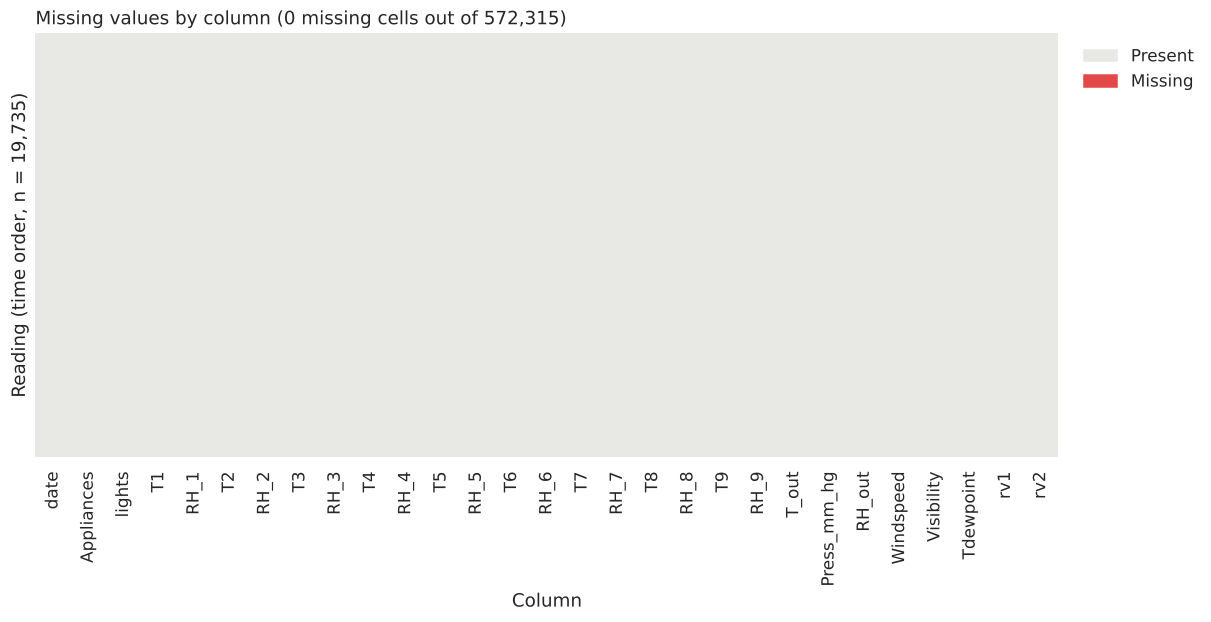

In [10]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(
    df.isnull(),
    cmap=ListedColormap(["#e8e8e4", COLOR_MISSING]),  # grey = present, red = missing
    vmin=0, vmax=1,                                    # fixed scale so an all-present matrix still renders grey
    cbar=False, yticklabels=False, ax=ax,
)
ax.set_title(f"Missing values by column ({n_missing_cells} missing cells out of {df.size:,})", loc="left")
ax.set_xlabel("Column")
ax.set_ylabel(f"Reading (time order, n = {len(df):,})")
ax.legend(handles=[Patch(color="#e8e8e4", label="Present"), Patch(color=COLOR_MISSING, label="Missing")],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
save_fig(fig, "task2_missing_heatmap")
plt.show()

### 2.3 Duplicate count and examples
Duplicates are checked at three levels: identical rows, identical sensor readings at different times, and repeated timestamps. Identical **columns** are checked too, because a copied feature is also a duplicate.

In [11]:
# (a) Row-level duplicates
dup_checks = pd.DataFrame({
    "check": [
        "Fully duplicated rows",
        "Identical readings at different times (all columns except date)",
        "Duplicated timestamps",
    ],
    "count": [
        df.duplicated().sum(),
        df.drop(columns="date").duplicated().sum(),
        df["date"].duplicated().sum(),
    ],
})
display(dup_checks)

dup_rows = df[df.drop(columns="date").duplicated(keep=False)]
if dup_rows.empty:
    print("No duplicated rows, so there are no row examples to show.")
else:
    display(dup_rows.head(10))

,check,count
0,Fully duplicated rows,0
1,Identical readings at different times (all col...,0
2,Duplicated timestamps,0


No duplicated rows, so there are no row examples to show.


In [12]:
# (b) Column-level duplicates: pairs of numeric columns with exactly the same values in every row
numeric_cols = df.select_dtypes("number").columns
dup_col_pairs = [
    (a, b)
    for i, a in enumerate(numeric_cols)
    for b in numeric_cols[i + 1:]
    if df[a].equals(df[b])
]
print(f"Identical column pairs: {dup_col_pairs}")

# Example rows showing the duplicated columns side by side
if dup_col_pairs:
    a, b = dup_col_pairs[0]
    display(df[["date", a, b]].head())
    print(f"Correlation of {a} with the target Appliances: r = {df[a].corr(df['Appliances']):.3f}")

Identical column pairs: [('rv1', 'rv2')]


,date,rv1,rv2
0,2016-01-11 17:00:00,13.275433,13.275433
1,2016-01-11 17:10:00,18.606195,18.606195
2,2016-01-11 17:20:00,28.642668,28.642668
3,2016-01-11 17:30:00,45.410389,45.410389
4,2016-01-11 17:40:00,10.084097,10.084097


Correlation of rv1 with the target Appliances: r = -0.011


### 2.4 Outliers
Three complementary checks:
1. **Boxplots** of every numerical column (visual).
2. **IQR rule** (values outside Q1 − 1.5·IQR and Q3 + 1.5·IQR), a purely statistical test.
3. **Physical plausibility**: values outside what the sensor or the physics allows, and values piling up at a sensor's limit.

#### 2.4.1 Boxplots for all numerical features

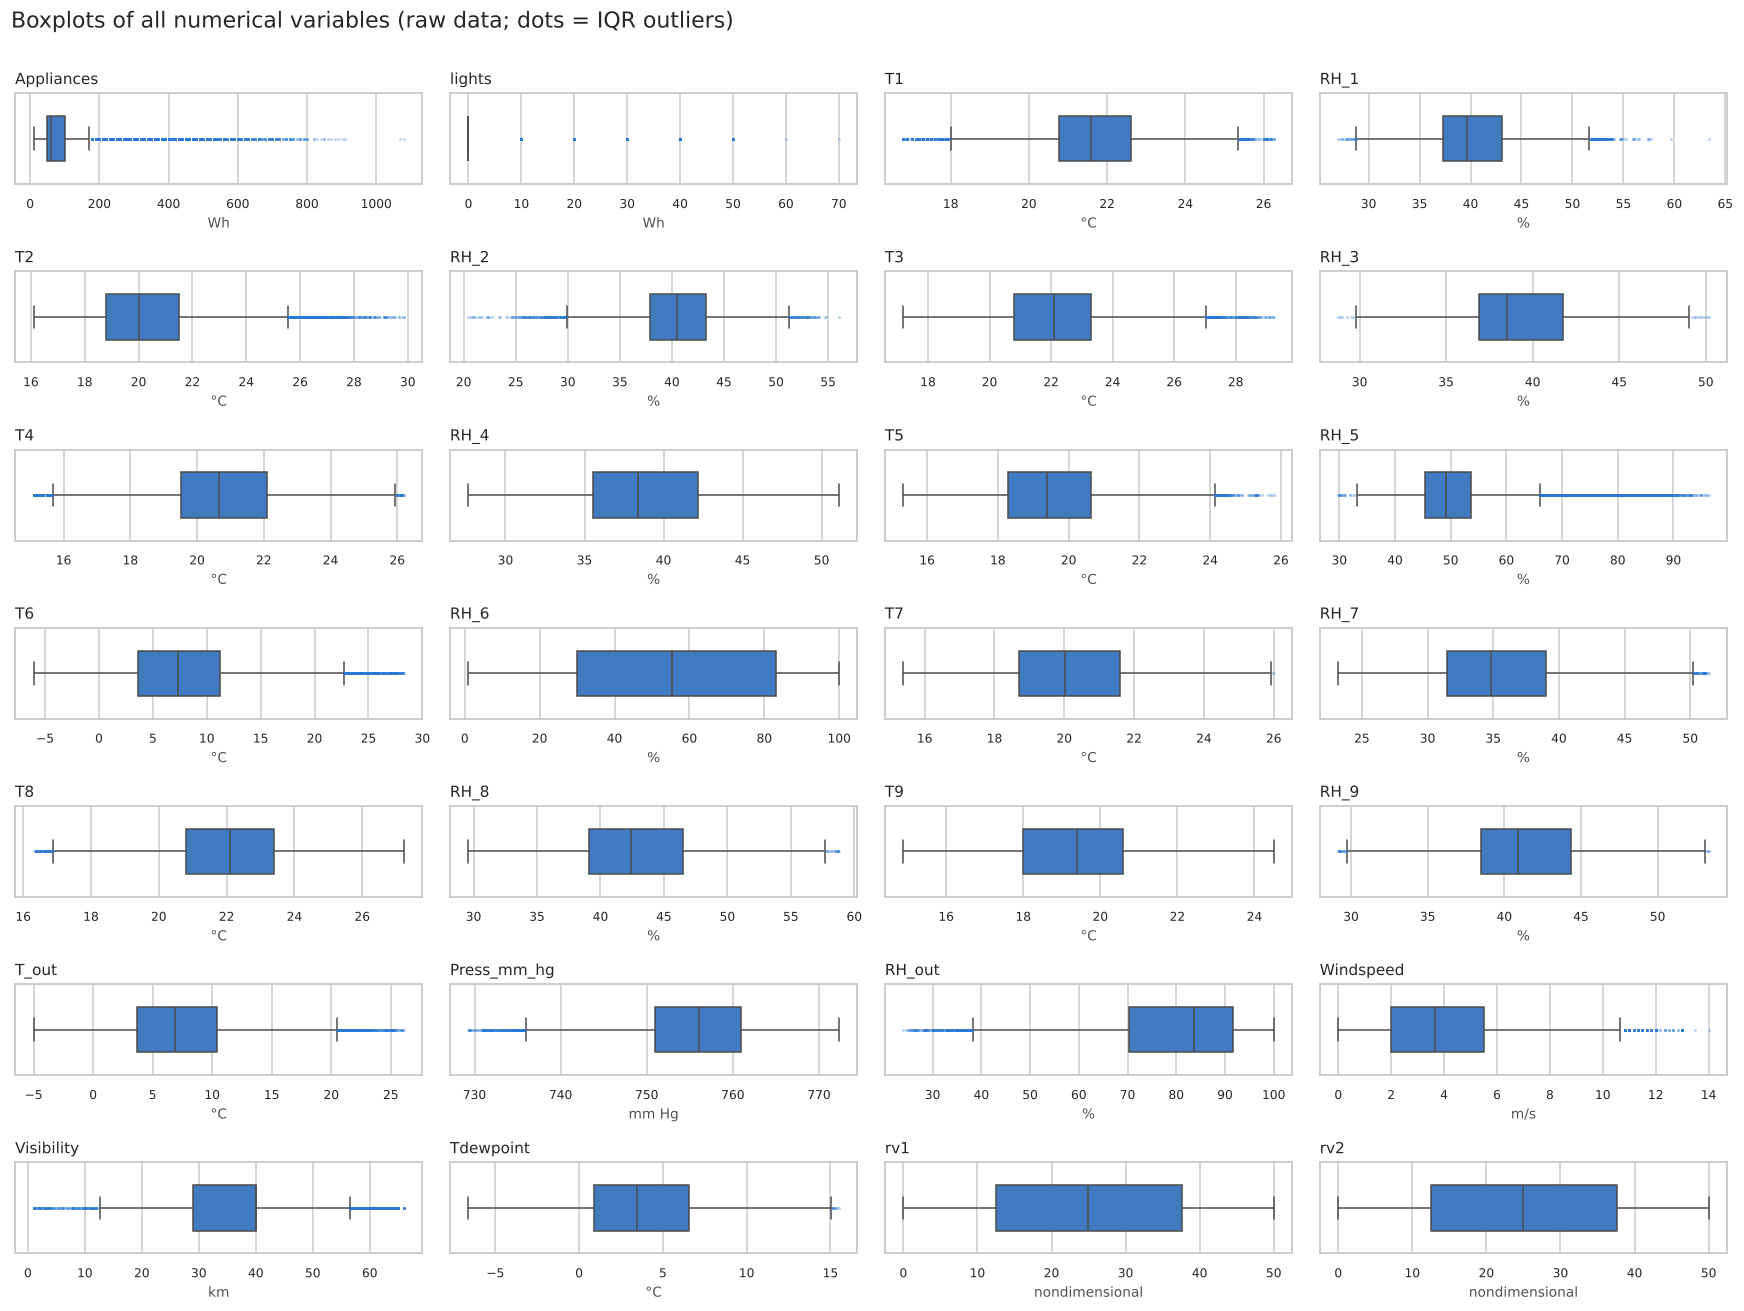

In [13]:
def plot_boxplot_grid(data, columns, n_cols=4, color=COLOR_MAIN):
    """Draw one horizontal boxplot per column, each on its own scale, with the unit on the x-axis."""
    n_rows = int(np.ceil(len(columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 1.7 * n_rows))
    for ax, col in zip(axes.flat, columns):
        sns.boxplot(
            x=data[col], ax=ax, color=color, width=0.5, linewidth=1,
            flierprops=dict(marker="o", markersize=2, alpha=0.3,
                            markerfacecolor=color, markeredgecolor="none"),
        )
        ax.set_title(col, loc="left", fontsize=10)
        ax.set_xlabel(UNITS.get(col, ""), fontsize=9, color=COLOR_TEXT)
        ax.tick_params(axis="x", labelsize=8)
    for ax in axes.flat[len(columns):]:   # hide unused panels in the last row
        ax.set_visible(False)
    return fig


fig = plot_boxplot_grid(df, numeric_cols)
fig.suptitle("Boxplots of all numerical variables (raw data; dots = IQR outliers)", x=0.01, ha="left", y=1.0)
fig.tight_layout()
save_fig(fig, "task2_boxplots")
plt.show()

#### 2.4.2 IQR outlier counts

In [14]:
def iqr_outlier_summary(data, columns, k=1.5):
    """Return lower/upper IQR fences and the number and % of values outside them for each column."""
    rows = []
    for col in columns:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        n_low = int((data[col] < lower).sum())
        n_high = int((data[col] > upper).sum())
        rows.append({
            "column": col, "unit": UNITS.get(col, ""),
            "lower_fence": round(lower, 2), "upper_fence": round(upper, 2),
            "n_below": n_low, "n_above": n_high,
            "outlier_count": n_low + n_high,
            "outlier_pct": round((n_low + n_high) / len(data) * 100, 2),
        })
    return pd.DataFrame(rows).set_index("column").sort_values("outlier_pct", ascending=False)


iqr_table = iqr_outlier_summary(df, numeric_cols)
display(iqr_table)

,unit,lower_fence,upper_fence,n_below,n_above,outlier_count,outlier_pct
column,,,,,,,
lights,Wh,0.00,0.00,0,4483,4483,22.72
Visibility,km,12.50,56.50,166,2356,2522,12.78
Appliances,Wh,-25.00,175.00,0,2138,2138,10.83
RH_5,%,33.01,66.06,16,1314,1330,6.74
T2,°C,14.72,25.57,0,546,546,2.77
T1,°C,18.00,25.36,249,266,515,2.61
T6,°C,-7.82,22.70,0,515,515,2.61
T_out,°C,-6.45,20.52,0,436,436,2.21
RH_out,%,38.33,123.67,239,0,239,1.21


#### 2.4.3 Physical plausibility checks
The IQR rule only measures distance from the middle of a distribution. It cannot tell whether a value is physically possible. Two extra checks use engineering limits instead:
- **Range check:** every value must be inside the valid range for its unit.
- **Sensor-limit check:** many readings sitting at exactly the minimum or maximum value can mean the sensor hit its measuring limit (clipping), not a real reading.
- **Repeated-value check:** one value making up a large share of readings can be a default or reporting cap rather than a measurement.

In [15]:
# Valid ranges by unit (physical limits, deliberately generous; None = no limit on that side)
VALID_RANGES = {
    "Wh": (0, None),        # energy cannot be negative
    "°C": (-30, 50),        # Belgian climate, indoor and outdoor
    "%": (0, 100),          # relative humidity
    "mm Hg": (700, 800),    # near sea-level atmospheric pressure
    "m/s": (0, None),
    "km": (0, None),
}

rows = []
for col in numeric_cols:
    unit = UNITS.get(col, "")
    if unit not in VALID_RANGES:          # rv1 / rv2 have no physical unit
        continue
    low, high = VALID_RANGES[unit]
    below = int((df[col] < low).sum()) if low is not None else 0
    above = int((df[col] > high).sum()) if high is not None else 0
    col_min, col_max = df[col].min(), df[col].max()
    mode_value = df[col].mode().iloc[0]
    rows.append({
        "column": col, "unit": unit, "valid_range": f"{low} to {high if high is not None else '∞'}",
        "min": round(col_min, 2), "max": round(col_max, 2), "out_of_range": below + above,
        "pct_at_min": round((df[col] == col_min).mean() * 100, 2),   # share of readings exactly at the minimum
        "pct_at_max": round((df[col] == col_max).mean() * 100, 2),   # share of readings exactly at the maximum
        "most_common_value": round(mode_value, 2),
        "pct_most_common": round((df[col] == mode_value).mean() * 100, 2),  # one value repeated very often
    })

physical_checks = pd.DataFrame(rows).set_index("column")
physical_checks["limit_pile_up"] = (physical_checks[["pct_at_min", "pct_at_max"]] > 1).any(axis=1)
display(physical_checks.sort_values(["limit_pile_up", "pct_at_min"], ascending=False))
print(f"Values outside their physical range: {physical_checks['out_of_range'].sum()}")
print(f"Columns with >1% of readings exactly at their min or max: "
      f"{list(physical_checks.index[physical_checks['limit_pile_up']])}")
print(f"Columns where a single value makes up >10% of readings: "
      f"{list(physical_checks.index[physical_checks['pct_most_common'] > 10])}")

,unit,valid_range,min,max,out_of_range,pct_at_min,pct_at_max,most_common_value,pct_most_common,limit_pile_up
column,,,,,,,,,,
lights,Wh,0 to ∞,0.00,70.00,0,77.28,0.01,0.00,77.28,True
RH_6,%,0 to 100,1.00,99.90,0,7.36,3.81,1.00,7.36,True
T2,°C,-30 to 50,16.10,29.86,0,0.09,0.01,19.20,1.68,False
T4,°C,-30 to 50,15.10,26.20,0,0.07,0.01,20.39,1.76,False
Appliances,Wh,0 to ∞,10.00,1080.00,0,0.05,0.01,50.00,22.13,False
T1,°C,-30 to 50,16.79,26.26,0,0.05,0.02,21.00,2.60,False
T9,°C,-30 to 50,14.89,24.50,0,0.05,0.10,20.50,2.47,False
Visibility,km,0 to ∞,1.00,66.00,0,0.05,0.04,40.00,36.61,False
Windspeed,m/s,0 to ∞,0.00,14.00,0,0.03,0.01,1.00,10.81,False


Values outside their physical range: 0
Columns with >1% of readings exactly at their min or max: ['lights', 'RH_6']
Columns where a single value makes up >10% of readings: ['Appliances', 'lights', 'Windspeed', 'Visibility']


#### 2.4.4 Investigating the outdoor humidity sensor (RH_6)
RH_6 (sensor on the north wall, outside) and RH_out (Chièvres weather station) measure the same physical quantity, outdoor relative humidity. Comparing them month by month shows whether RH_6 can be trusted.

In [16]:
rh6_min, rh6_max = df["RH_6"].min(), df["RH_6"].max()
at_min = df["RH_6"] == rh6_min
at_max = df["RH_6"] == rh6_max

# Monthly comparison of the wall sensor and the weather station
rh_check = (
    df.assign(month=timestamps.dt.to_period("M"),
              rh6_at_min=at_min, rh6_at_max=at_max,
              t6_minus_tout=df["T6"] - df["T_out"])
      .groupby("month")
      .agg(RH_6_mean=("RH_6", "mean"), RH_out_mean=("RH_out", "mean"),
           pct_RH_6_at_min=("rh6_at_min", "mean"), pct_RH_6_at_max=("rh6_at_max", "mean"),
           T6_minus_T_out_mean=("t6_minus_tout", "mean"))
)
rh_check[["pct_RH_6_at_min", "pct_RH_6_at_max"]] *= 100
display(rh_check.round(2))

print(f"RH_6 readings exactly at {rh6_min}%: {at_min.sum():,} | exactly at {rh6_max}%: {at_max.sum():,}")
print(f"First reading at {rh6_min}%: {timestamps[at_min].min()}")
print(f"Hours of day when RH_6 = {rh6_min}%: {timestamps[at_min].dt.hour.min()}:00 to {timestamps[at_min].dt.hour.max()}:59")
print(f"RH_out (weather station) at those same times: {df.loc[at_min, 'RH_out'].min():.0f}% to {df.loc[at_min, 'RH_out'].max():.0f}%")
print(f"Mean T6 - T_out: {(df['T6'] - df['T_out'])[at_min].mean():.2f} °C when RH_6 = {rh6_min}%, "
      f"{(df['T6'] - df['T_out'])[~at_min].mean():.2f} °C otherwise")

,RH_6_mean,RH_out_mean,pct_RH_6_at_min,pct_RH_6_at_max,T6_minus_T_out_mean
month,,,,,
2016-01,92.18,86.61,0.00,21.80,-0.23
2016-02,79.96,84.23,0.00,2.73,0.06
2016-03,54.87,80.73,0.00,0.00,0.42
2016-04,34.09,77.21,5.69,0.00,0.76
2016-05,21.34,71.40,31.30,0.00,1.33


RH_6 readings exactly at 1.0%: 1,452 | exactly at 99.9%: 751
First reading at 1.0%: 2016-04-09 14:30:00
Hours of day when RH_6 = 1.0%: 8:00 to 21:59
RH_out (weather station) at those same times: 24% to 81%
Mean T6 - T_out: 2.44 °C when RH_6 = 1.0%, 0.35 °C otherwise


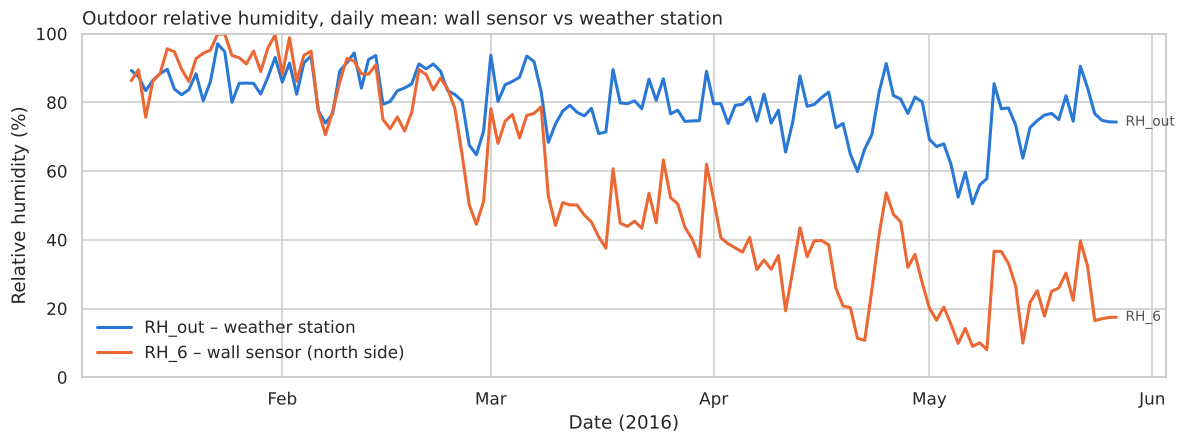

In [17]:
# Daily means make the long-term drift visible (10-minute data is too dense to read)
daily = df.groupby(timestamps.dt.date)[["RH_6", "RH_out"]].mean()
daily.index = pd.to_datetime(daily.index)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(daily.index, daily["RH_out"], color=COLOR_MAIN, linewidth=2, label="RH_out – weather station")
ax.plot(daily.index, daily["RH_6"], color=COLOR_SECOND, linewidth=2, label="RH_6 – wall sensor (north side)")
# Direct labels at the right-hand end of each line
for col, color in [("RH_out", COLOR_MAIN), ("RH_6", COLOR_SECOND)]:
    ax.annotate(col, xy=(daily.index[-1], daily[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=COLOR_TEXT, fontsize=9)
ax.set_ylim(0, 100)
ax.xaxis.set_major_locator(matplotlib.dates.MonthLocator())
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
ax.set_title("Outdoor relative humidity, daily mean: wall sensor vs weather station", loc="left")
ax.set_xlabel("Date (2016)")
ax.set_ylabel("Relative humidity (%)")
ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
save_fig(fig, "task2_rh6_vs_rhout")
plt.show()

### 2.5 Cleaning decisions and data types after cleaning
Every decision is recorded in a cleaning log so it can be copied into the report. **No rows are removed**: the target is a time series, and deleting readings would leave gaps in it.

> The columns to drop are set in one place (`DROP_COLUMNS`). Review each decision and edit the list if you choose differently.

In [18]:
# Columns removed and the evidence for each (from 2.3 and 2.4)
DROP_COLUMNS = {
    "rv1": "Random variable added by the dataset authors (no physical meaning); r with target ≈ 0 (2.3)",
    "rv2": "Exact duplicate of rv1 (2.3)",
    "RH_6": "Wall sensor drifts and clips at its limits (2.4.4); RH_out measures the same quantity reliably",
}

cleaning_log = []


def log_step(step, action, reason, shape_before, shape_after):
    """Record one cleaning step for the report."""
    cleaning_log.append({"step": step, "action": action, "reason": reason,
                         "shape_before": shape_before, "shape_after": shape_after})


df_clean = df.copy()

# Step 1 – convert the timestamp from text to datetime
before = df_clean.shape
df_clean["date"] = pd.to_datetime(df_clean["date"], format="%Y-%m-%d %H:%M:%S")
log_step("Data type", "date: text -> datetime64",
         "Enables time-based analysis (hour, weekday) and correct sorting", before, df_clean.shape)

# Step 2 – remove columns that carry no reliable information
for col, reason in DROP_COLUMNS.items():
    before = df_clean.shape
    df_clean = df_clean.drop(columns=col)
    log_step("Drop column", f"Removed {col}", reason, before, df_clean.shape)

# Step 3 – duplicates: nothing to remove (2.3)
log_step("Duplicates", "None removed", "0 duplicated rows and 0 duplicated timestamps", df_clean.shape, df_clean.shape)

# Step 4 – outliers: kept (2.4)
log_step("Outliers", "Kept, no rows removed",
         "All values inside physical ranges (2.4.3); review in 2.6", df_clean.shape, df_clean.shape)

display(pd.DataFrame(cleaning_log))

,step,action,reason,shape_before,shape_after
0,Data type,date: text -> datetime64,"Enables time-based analysis (hour, weekday) an...","(19735, 29)","(19735, 29)"
1,Drop column,Removed rv1,Random variable added by the dataset authors (...,"(19735, 29)","(19735, 28)"
2,Drop column,Removed rv2,Exact duplicate of rv1 (2.3),"(19735, 28)","(19735, 27)"
3,Drop column,Removed RH_6,Wall sensor drifts and clips at its limits (2....,"(19735, 27)","(19735, 26)"
4,Duplicates,None removed,0 duplicated rows and 0 duplicated timestamps,"(19735, 26)","(19735, 26)"
5,Outliers,"Kept, no rows removed",All values inside physical ranges (2.4.3); rev...,"(19735, 26)","(19735, 26)"


In [19]:
# Data types after cleaning
dtypes_after = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "unit": [UNITS.get(c, "") for c in df_clean.columns],
    "n_unique": df_clean.nunique(),
})
display(dtypes_after)
print(f"Shape before cleaning: {df.shape} | after cleaning: {df_clean.shape}")

# From here on, `df` is the cleaned dataset (`df_raw` still holds the original)
df = df_clean

,dtype,unit,n_unique
date,datetime64[us],-,19735
Appliances,int64,Wh,92
lights,int64,Wh,8
T1,float64,°C,722
RH_1,float64,%,2547
T2,float64,°C,1650
RH_2,float64,%,3376
T3,float64,°C,1426
RH_3,float64,%,2618
T4,float64,°C,1390


Shape before cleaning: (19735, 29) | after cleaning: (19735, 26)


### 2.6 Task 2 observations

**Missing values and duplicates.** No column has missing values (0 of 572,315 cells), and the time index is complete: all 19,735 expected 10-minute steps between 11 January and 27 May 2016 are present, with no repeated timestamps. There are no duplicated rows, and no two readings are identical even when the timestamp is ignored, so no imputation or row removal was needed. The only duplication is at column level: `rv1` and `rv2` are identical in every row. They are random variables that the dataset authors added on purpose to test feature selection, they have no physical meaning, and their correlation with the target is r = −0.011, so both were removed.

**Outliers (IQR rule).** The IQR rule flags many values, but most of them are not errors:
- `lights` (22.7% flagged): 77.3% of readings are 0, so Q1 = Q3 = 0 and every reading with the lights on falls outside the fences. The IQR rule is not suitable for a zero-inflated variable.
- `Visibility` (12.8%): 36.6% of readings are exactly 40 km, which squeezes the IQR. This spike is probably a default or rounded value reported by the weather station rather than a true measurement.
- `Appliances` (10.8%, all above 175 Wh): the target is strongly right-skewed. 175 Wh in 10 minutes is about 1 kW of average power, and the maximum (1,080 Wh ≈ 6.5 kW) is realistic for an oven, kettle or washing machine running at the same time. These peaks are the events a model most needs to predict, so they were kept.
- `RH_5` (6.7%): bathroom humidity of up to 96% is consistent with showers.

All values are inside physically valid ranges, so no outliers were removed or capped.

**Sensor fault in RH_6.** The physical checks found a problem that the IQR rule missed (RH_6 has 0 IQR outliers because its values cover almost the whole 1–99.9% range). RH_6 and the weather station's RH_out measure the same quantity, outdoor relative humidity. They agreed in January (monthly means 92% vs 87%), but RH_6 then drifted steadily downwards to 21% in May while RH_out stayed above 70%. RH_6 also sits exactly at its measuring limits: 751 readings at 99.9% (mostly in January) and 1,452 readings at 1.0% (from 9 April onwards, only between 08:00 and 22:00, while the station reported 24–81%). During the 1.0% readings the wall sensor was on average 2.4 °C warmer than the outdoor air, compared with 0.35 °C at other times, which suggests the sensor was being heated, for example by the façade or by the sun. A warmer sensor reports a lower relative humidity, but this alone cannot explain a reading of 1%, so a gradual sensor fault is the most likely cause. Because the drift affects every reading from March onwards, not only the clipped ones, replacing the clipped values with NaN and interpolating would not fix the problem. RH_6 was therefore dropped; RH_out provides the same information from a reliable source.

**Result.** `date` was converted from text to datetime64 so that time-based features can be created. After removing `rv1`, `rv2` and `RH_6`, the cleaned dataset has 19,735 rows × 26 columns: one datetime column, two int64 columns (`Appliances`, `lights`) and 23 float64 sensor columns.

## 3. Task 3 – Target Variable Preparation
The target `Appliances` is numeric, so (following the brief) it is converted into a small number of classes. The numeric column is **kept** next to the class label: correlations in Task 5 use the numeric values.

### 3.1 Target variable name, data type and problem type

In [20]:
TARGET = "Appliances"          # numeric target (energy used by appliances in each 10-minute interval)
y = df[TARGET]

step_sizes = np.unique(np.diff(np.sort(y.unique())))   # gaps between neighbouring distinct values
target_info = pd.Series({
    "column": TARGET,
    "description": VARIABLES[TARGET][0],
    "unit": f"{UNITS[TARGET]} per 10-minute interval",
    "dtype": str(y.dtype),
    "distinct values": y.nunique(),
    "smallest step between values": f"{step_sizes.min()} {UNITS[TARGET]}",
    "all values multiples of 10": bool((y % 10 == 0).all()),
    "range": f"{y.min()} to {y.max()} {UNITS[TARGET]}",
    # Wh used in 10 minutes x 6 = average power in W over that interval
    "range as average power": f"{y.min() * 6} to {y.max() * 6:,} W",
    "original problem type": "Regression (continuous numeric target)",
    "problem type used here": "Classification (target converted to classes in 3.3)",
}, name="value")
display(target_info.to_frame())

,value
column,Appliances
description,Energy use of appliances (TARGET)
unit,Wh per 10-minute interval
dtype,int64
distinct values,92
smallest step between values,10 Wh
all values multiples of 10,True
range,10 to 1080 Wh
range as average power,"60 to 6,480 W"
original problem type,Regression (continuous numeric target)


### 3.2 Target distribution and summary statistics

In [21]:
q1, median, q3 = y.quantile([0.25, 0.5, 0.75])
target_stats = pd.Series({
    "mean": y.mean(), "median": median, "std": y.std(),
    "min": y.min(), "Q1 (25%)": q1, "Q3 (75%)": q3, "max": y.max(),
    "90th percentile": y.quantile(0.90), "99th percentile": y.quantile(0.99),
    "skewness": y.skew(), "kurtosis (excess)": y.kurt(),
    "skewness of log10(target)": np.log10(y).skew(),
}, name=TARGET).round(2)
display(target_stats.to_frame())

# The most frequent values (the target is recorded in 10 Wh steps, so many readings share a value)
top_values = (y.value_counts(normalize=True).mul(100).round(2)
                .rename("pct_of_readings").head(6).to_frame())
top_values["cumulative_pct_from_lowest"] = [round((y <= v).mean() * 100, 1) for v in top_values.index]
display(top_values)

,Appliances
mean,97.69
median,60.00
std,102.52
min,10.00
Q1 (25%),50.00
Q3 (75%),100.00
max,1080.00
90th percentile,196.00
99th percentile,576.60
skewness,3.39


,pct_of_readings,cumulative_pct_from_lowest
Appliances,,
50,22.13,37.8
60,16.63,54.4
40,10.23,15.7
70,7.90,62.3
80,6.11,68.5
90,5.14,73.6


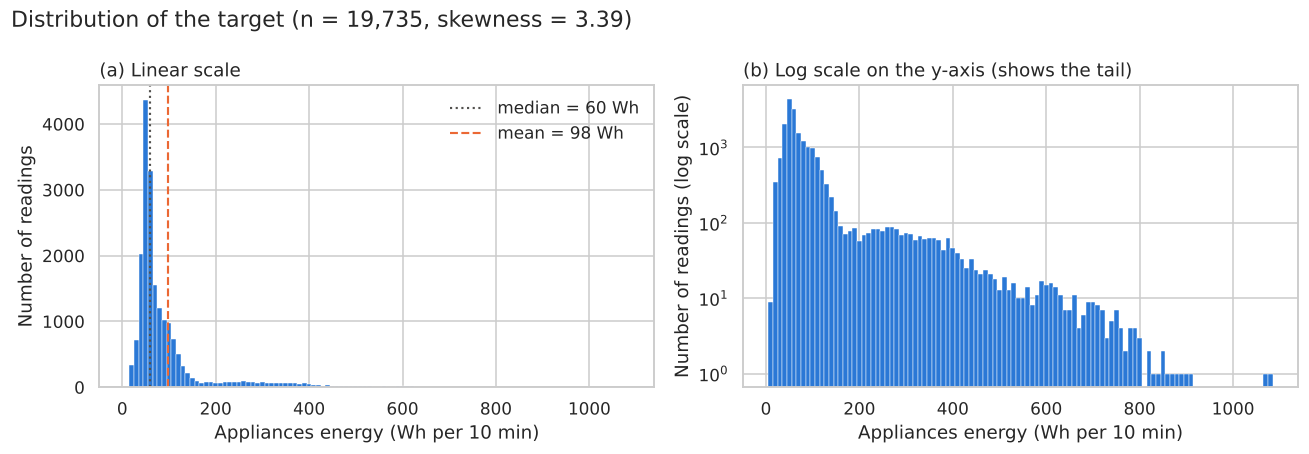

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# (a) Linear scale: bins 10 Wh wide, matching the resolution of the meter
bins = np.arange(y.min() - 5, y.max() + 15, 10)
axes[0].hist(y, bins=bins, color=COLOR_MAIN, edgecolor="white", linewidth=0.3)
# Median and mean as reference lines, named in the legend (the two lines are too close for text labels)
axes[0].axvline(median, color=COLOR_TEXT, linestyle=":", linewidth=1.4, label=f"median = {median:.0f} Wh")
axes[0].axvline(y.mean(), color=COLOR_SECOND, linestyle="--", linewidth=1.4, label=f"mean = {y.mean():.0f} Wh")
axes[0].legend(loc="upper right", frameon=False)
axes[0].set_title("(a) Linear scale", loc="left")
axes[0].set_xlabel("Appliances energy (Wh per 10 min)")
axes[0].set_ylabel("Number of readings")

# (b) Same histogram with a log y-axis: makes the long right tail (rare high readings) visible
axes[1].hist(y, bins=bins, color=COLOR_MAIN, edgecolor="white", linewidth=0.3)
axes[1].set_yscale("log")
axes[1].set_title("(b) Log scale on the y-axis (shows the tail)", loc="left")
axes[1].set_xlabel("Appliances energy (Wh per 10 min)")
axes[1].set_ylabel("Number of readings (log scale)")

fig.suptitle(f"Distribution of the target (n = {len(y):,}, skewness = {y.skew():.2f})", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "task3_target_distribution")
plt.show()

### 3.3 Discretising the target into 3–5 classes
Two standard binning methods are compared for 3, 4 and 5 classes:
- **Equal-width** (`pd.cut`): splits the value range into intervals of the same size.
- **Equal-frequency** (`pd.qcut`): places boundaries at quantiles so each class gets a similar number of readings.

Because the target only takes multiples of 10 Wh, a boundary always falls **between** two meter values, and readings with the same value always stay in the same class. (Ranking the readings to force perfectly equal classes would put identical readings into different classes, so it is not used.)

Balance is measured with the **balance ratio** = smallest class ÷ largest class (1.0 = perfectly balanced).

In [23]:
def describe_binning(series, binned):
    """Summarise a binning: class edges, % of readings per class and the balance ratio."""
    shares = binned.value_counts(normalize=True, sort=False).mul(100)
    edges = [binned.cat.categories[0].left] + [interval.right for interval in binned.cat.categories]
    return {
        "edges (Wh)": ", ".join(f"{e:.0f}" for e in edges),
        "class shares (%)": " / ".join(f"{s:.1f}" for s in shares),
        "largest class (%)": round(shares.max(), 1),
        "balance ratio": round(shares.min() / shares.max(), 3),
    }


rows = []
for k in [3, 4, 5]:
    rows.append({"method": "Equal-width", "k": k, **describe_binning(y, pd.cut(y, bins=k))})
    rows.append({"method": "Equal-frequency", "k": k,
                 **describe_binning(y, pd.qcut(y, q=k, duplicates="drop"))})

binning_comparison = pd.DataFrame(rows).set_index(["method", "k"])
display(binning_comparison)

,,edges (Wh),class shares (%),largest class (%),balance ratio
method,k,,,,
Equal-width,3,"9, 367, 723, 1080",96.2 / 3.6 / 0.2,96.2,0.002
Equal-frequency,3,"10, 50, 80, 1080",37.8 / 30.6 / 31.5,37.8,0.810
Equal-width,4,"9, 278, 545, 812, 1080",93.1 / 5.7 / 1.1 / 0.1,93.1,0.001
Equal-frequency,4,"10, 50, 60, 100, 1080",37.8 / 16.6 / 24.1 / 21.4,37.8,0.440
Equal-width,5,"9, 224, 438, 652, 866, 1080",91.0 / 6.7 / 1.7 / 0.5 / 0.0,91.0,0.000
Equal-frequency,5,"10, 50, 60, 70, 110, 1080",37.8 / 16.6 / 7.9 / 19.9 / 17.7,37.8,0.209


Class boundaries: 50 Wh and 80 Wh (= 300 W and 480 W average power)


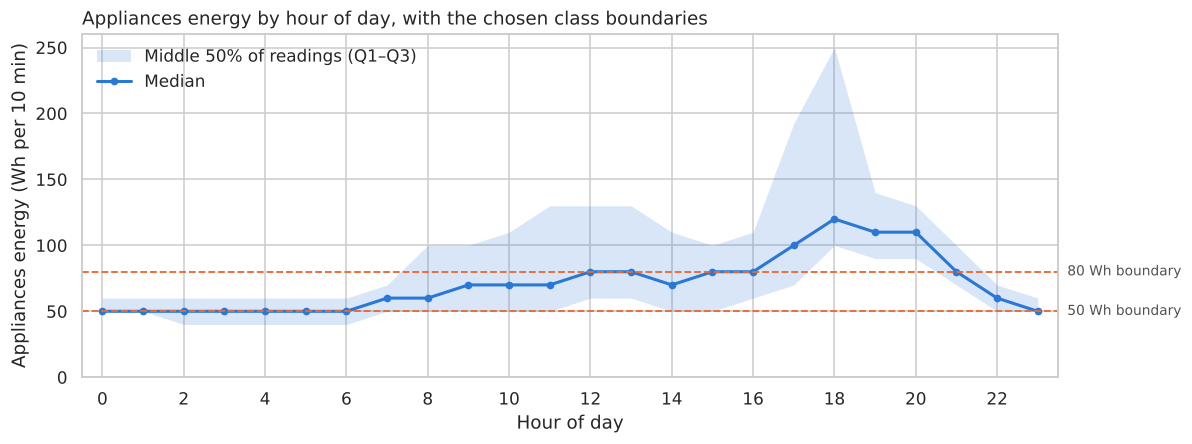

date,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Q1,50,50,40,40,40,40,40,50,50,50,50,50,60,60,50,50,60,70,100,90,90,70,50,50
median,50,50,50,50,50,50,50,60,60,70,70,70,80,80,70,80,80,100,120,110,110,80,60,50
Q3,60,60,60,60,60,60,60,70,100,100,110,130,130,130,110,100,110,192,250,140,130,100,70,60


In [24]:
# Typical consumption by hour of day: links the class boundaries to how the house is used
hourly = y.groupby(df["date"].dt.hour).quantile([0.25, 0.5, 0.75]).unstack()
hourly.columns = ["Q1", "median", "Q3"]

# Chosen scheme: equal-frequency with 3 classes (see 3.5). Boundaries come from the data, not typed in by hand.
CLASS_EDGES = [-np.inf] + list(pd.qcut(y, q=3, duplicates="drop").cat.categories.right[:-1]) + [np.inf]
CLASS_LABELS = ["Low", "Medium", "High"]
print(f"Class boundaries: {CLASS_EDGES[1]:.0f} Wh and {CLASS_EDGES[2]:.0f} Wh "
      f"(= {CLASS_EDGES[1] * 6:.0f} W and {CLASS_EDGES[2] * 6:.0f} W average power)")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(hourly.index, hourly["Q1"], hourly["Q3"], color=COLOR_MAIN, alpha=0.18, linewidth=0,
                label="Middle 50% of readings (Q1–Q3)")
ax.plot(hourly.index, hourly["median"], color=COLOR_MAIN, linewidth=2, marker="o", markersize=4,
        label="Median")
for edge in CLASS_EDGES[1:-1]:
    ax.axhline(edge, color=COLOR_SECOND, linestyle="--", linewidth=1.2)
    ax.annotate(f"{edge:.0f} Wh boundary", xy=(1, edge), xycoords=("axes fraction", "data"),
                xytext=(6, 0), textcoords="offset points", va="center", color=COLOR_TEXT, fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, None)
ax.set_title("Appliances energy by hour of day, with the chosen class boundaries", loc="left")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Appliances energy (Wh per 10 min)")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
save_fig(fig, "task3_hourly_profile")
plt.show()

display(hourly.T.astype(int))

In [25]:
# Create the class label (ordered categorical) next to the numeric target
CLASS_COL = "Appliances_class"
df[CLASS_COL] = pd.cut(y, bins=CLASS_EDGES, labels=CLASS_LABELS, ordered=True)

class_table = (
    df.groupby(CLASS_COL, observed=False)[TARGET]
      .agg(count="size", min_Wh="min", max_Wh="max", median_Wh="median")
)
class_table["pct"] = (class_table["count"] / len(df) * 100).round(1)
class_table["avg_power_range_W"] = [f"{lo * 6}–{hi * 6:,}" for lo, hi in zip(class_table["min_Wh"], class_table["max_Wh"])]
display(class_table)
print(f"Balance ratio (smallest / largest class): {class_table['count'].min() / class_table['count'].max():.2f}")

,count,min_Wh,max_Wh,median_Wh,pct,avg_power_range_W
Appliances_class,,,,,,
Low,7462,10,50,50.0,37.8,60–300
Medium,6047,60,80,60.0,30.6,360–480
High,6226,90,1080,120.0,31.5,"540–6,480"


Balance ratio (smallest / largest class): 0.81


### 3.4 Class distribution of the chosen labelling
The rejected equal-width scheme is shown next to the chosen one, on the same scale, to make the difference in balance visible.

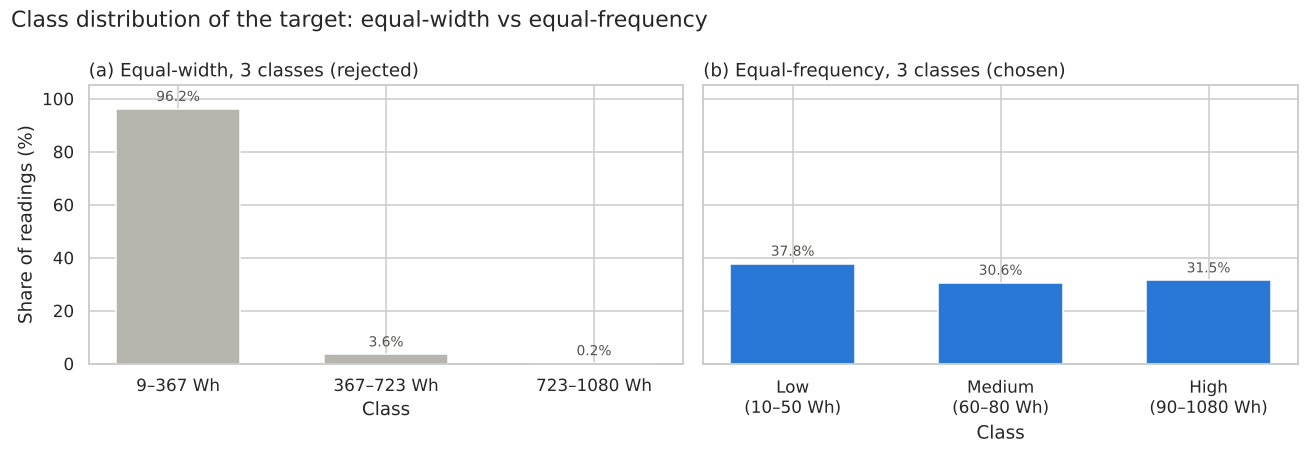

In [26]:
equal_width = pd.cut(y, bins=3)
ew_shares = equal_width.value_counts(normalize=True, sort=False).mul(100)
ew_labels = [f"{iv.left:.0f}–{iv.right:.0f} Wh" for iv in ew_shares.index]
chosen_shares = class_table["pct"]
chosen_labels = [f"{label}\n({lo}–{hi} Wh)" for label, lo, hi in
                 zip(class_table.index, class_table["min_Wh"], class_table["max_Wh"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
panels = [
    (axes[0], ew_labels, ew_shares.values, "#b5b4ad", "(a) Equal-width, 3 classes (rejected)"),
    (axes[1], chosen_labels, chosen_shares.values, COLOR_MAIN, "(b) Equal-frequency, 3 classes (chosen)"),
]
for ax, labels, shares, color, title in panels:
    bars = ax.bar(labels, shares, color=color, width=0.6)
    ax.bar_label(bars, labels=[f"{s:.1f}%" for s in shares], padding=3, fontsize=9, color=COLOR_TEXT)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Class")
axes[0].set_ylabel("Share of readings (%)")
axes[0].set_ylim(0, 105)
fig.suptitle("Class distribution of the target: equal-width vs equal-frequency", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "task3_class_distribution")
plt.show()

### 3.5 Task 3 observations

**Distribution.** `Appliances` is an integer meter reading recorded in 10 Wh steps (92 distinct values from 10 to 1,080 Wh per 10 minutes, i.e. 60–6,480 W of average power). It is strongly right-skewed (skewness 3.39, excess kurtosis 13.67): the mean (97.7 Wh) is far above the median (60 Wh), almost 40% of all readings are exactly 50 or 60 Wh, and a long tail reaches 1,080 Wh (90th percentile 196 Wh, 99th percentile 577 Wh). The log-scale plot shows that the tail decreases gradually up to about 800 Wh, with only a handful of readings above that, so the high values are a continuous range of real usage rather than a few isolated errors. Even log10(Appliances) still has a skewness of 1.17, so a log transform alone would not make the target symmetric.

**Choice of binning.** Equal-width binning puts 96.2% of readings into the lowest class (93.1% and 91.0% with 4 and 5 classes), far above the 80% level that the brief treats as severe imbalance, because the long tail stretches the value range. Equal-frequency binning gives much better balance. With 3 classes the boundaries fall at 50 and 80 Wh, and the classes hold 37.8%, 30.6% and 31.5% of readings (balance ratio 0.81). With 4 or 5 classes the balance ratio drops to 0.44 and 0.21: the very common values 50 and 60 Wh cannot be split, which leaves classes of only 16.6% and 7.9%. I therefore chose 3 equal-frequency classes. The classes cannot be exactly equal because all readings with the same value must stay in the same class, but 37.8 / 30.6 / 31.5% is reasonably balanced.

**Physical meaning.** Multiplying by 6 converts Wh per 10 minutes into average power:
- **Low (≤ 50 Wh, ≤ 300 W):** base load. Between 00:00 and 06:00 the median is exactly 50 Wh, which matches always-on appliances such as the fridge and devices on standby.
- **Medium (60–80 Wh, 360–480 W):** light daytime activity; the hourly median between 09:00 and 16:00 is 70–80 Wh.
- **High (≥ 90 Wh, ≥ 540 W):** active use of high-power appliances. The evening peak (17:00–20:00, median 100–120 Wh, Q3 up to 250 Wh at 18:00) falls in this class, consistent with cooking.

The High class is very wide (90–1,080 Wh), so it groups moderate and extreme usage together; this is a limitation of the 3-class scheme.

**Implications.** The numeric target is kept next to the class label, because correlations in Task 5 should use the original values (binning loses information). The labels are ordinal (Low < Medium < High), and the strong pattern over the hours of the day suggests that time features will be important predictors.

## 4. Task 4 – Univariate Analysis
Each predictor is examined on its own: what it measures, how its values are distributed, and what shape the distribution has.

### 4.1 List of all predictors
Predictors are every column except the target (`Appliances`) and its class label (`Appliances_class`). They are grouped by what they measure. `date` is not used directly as a predictor; it is the source of time features such as hour of day (see Task 3).

In [27]:
PREDICTOR_GROUPS = {
    "Energy (lighting)": ["lights"],
    "Indoor temperature": ["T1", "T2", "T3", "T4", "T5", "T7", "T8", "T9"],
    "Indoor humidity": ["RH_1", "RH_2", "RH_3", "RH_4", "RH_5", "RH_7", "RH_8", "RH_9"],
    "Outdoor – wall sensor": ["T6"],
    "Outdoor – weather station": ["T_out", "Tdewpoint", "RH_out", "Press_mm_hg", "Windspeed", "Visibility"],
}
PREDICTORS = [col for cols in PREDICTOR_GROUPS.values() for col in cols]

# Safety check: the grouping covers exactly the numeric columns left after cleaning (minus the target)
expected = set(df.select_dtypes("number").columns) - {TARGET}
assert set(PREDICTORS) == expected, f"Grouping mismatch: {set(PREDICTORS) ^ expected}"

predictor_table = pd.DataFrame(
    [(group, col, VARIABLES[col][0], UNITS[col], str(df[col].dtype))
     for group, cols in PREDICTOR_GROUPS.items() for col in cols],
    columns=["group", "predictor", "description", "unit", "dtype"],
).set_index("predictor")
display(predictor_table)
print(f"Number of predictors: {len(PREDICTORS)} (all numerical); excluded: date, {TARGET}, {CLASS_COL}")

,group,description,unit,dtype
predictor,,,,
lights,Energy (lighting),Energy use of light fixtures,Wh,int64
T1,Indoor temperature,Temperature – kitchen,°C,float64
T2,Indoor temperature,Temperature – living room,°C,float64
T3,Indoor temperature,Temperature – laundry room,°C,float64
T4,Indoor temperature,Temperature – office,°C,float64
T5,Indoor temperature,Temperature – bathroom,°C,float64
T7,Indoor temperature,Temperature – ironing room,°C,float64
T8,Indoor temperature,Temperature – teenager room 2,°C,float64
T9,Indoor temperature,Temperature – parents room,°C,float64


Number of predictors: 24 (all numerical); excluded: date, Appliances, Appliances_class


### 4.2 Distribution plots for numerical predictors
All 24 predictors are plotted (the brief asks for at least 6), as histograms with a KDE curve. Variables with only a few distinct values (`lights`) are drawn as discrete bars without a KDE, because a smooth curve would invent values that cannot occur.

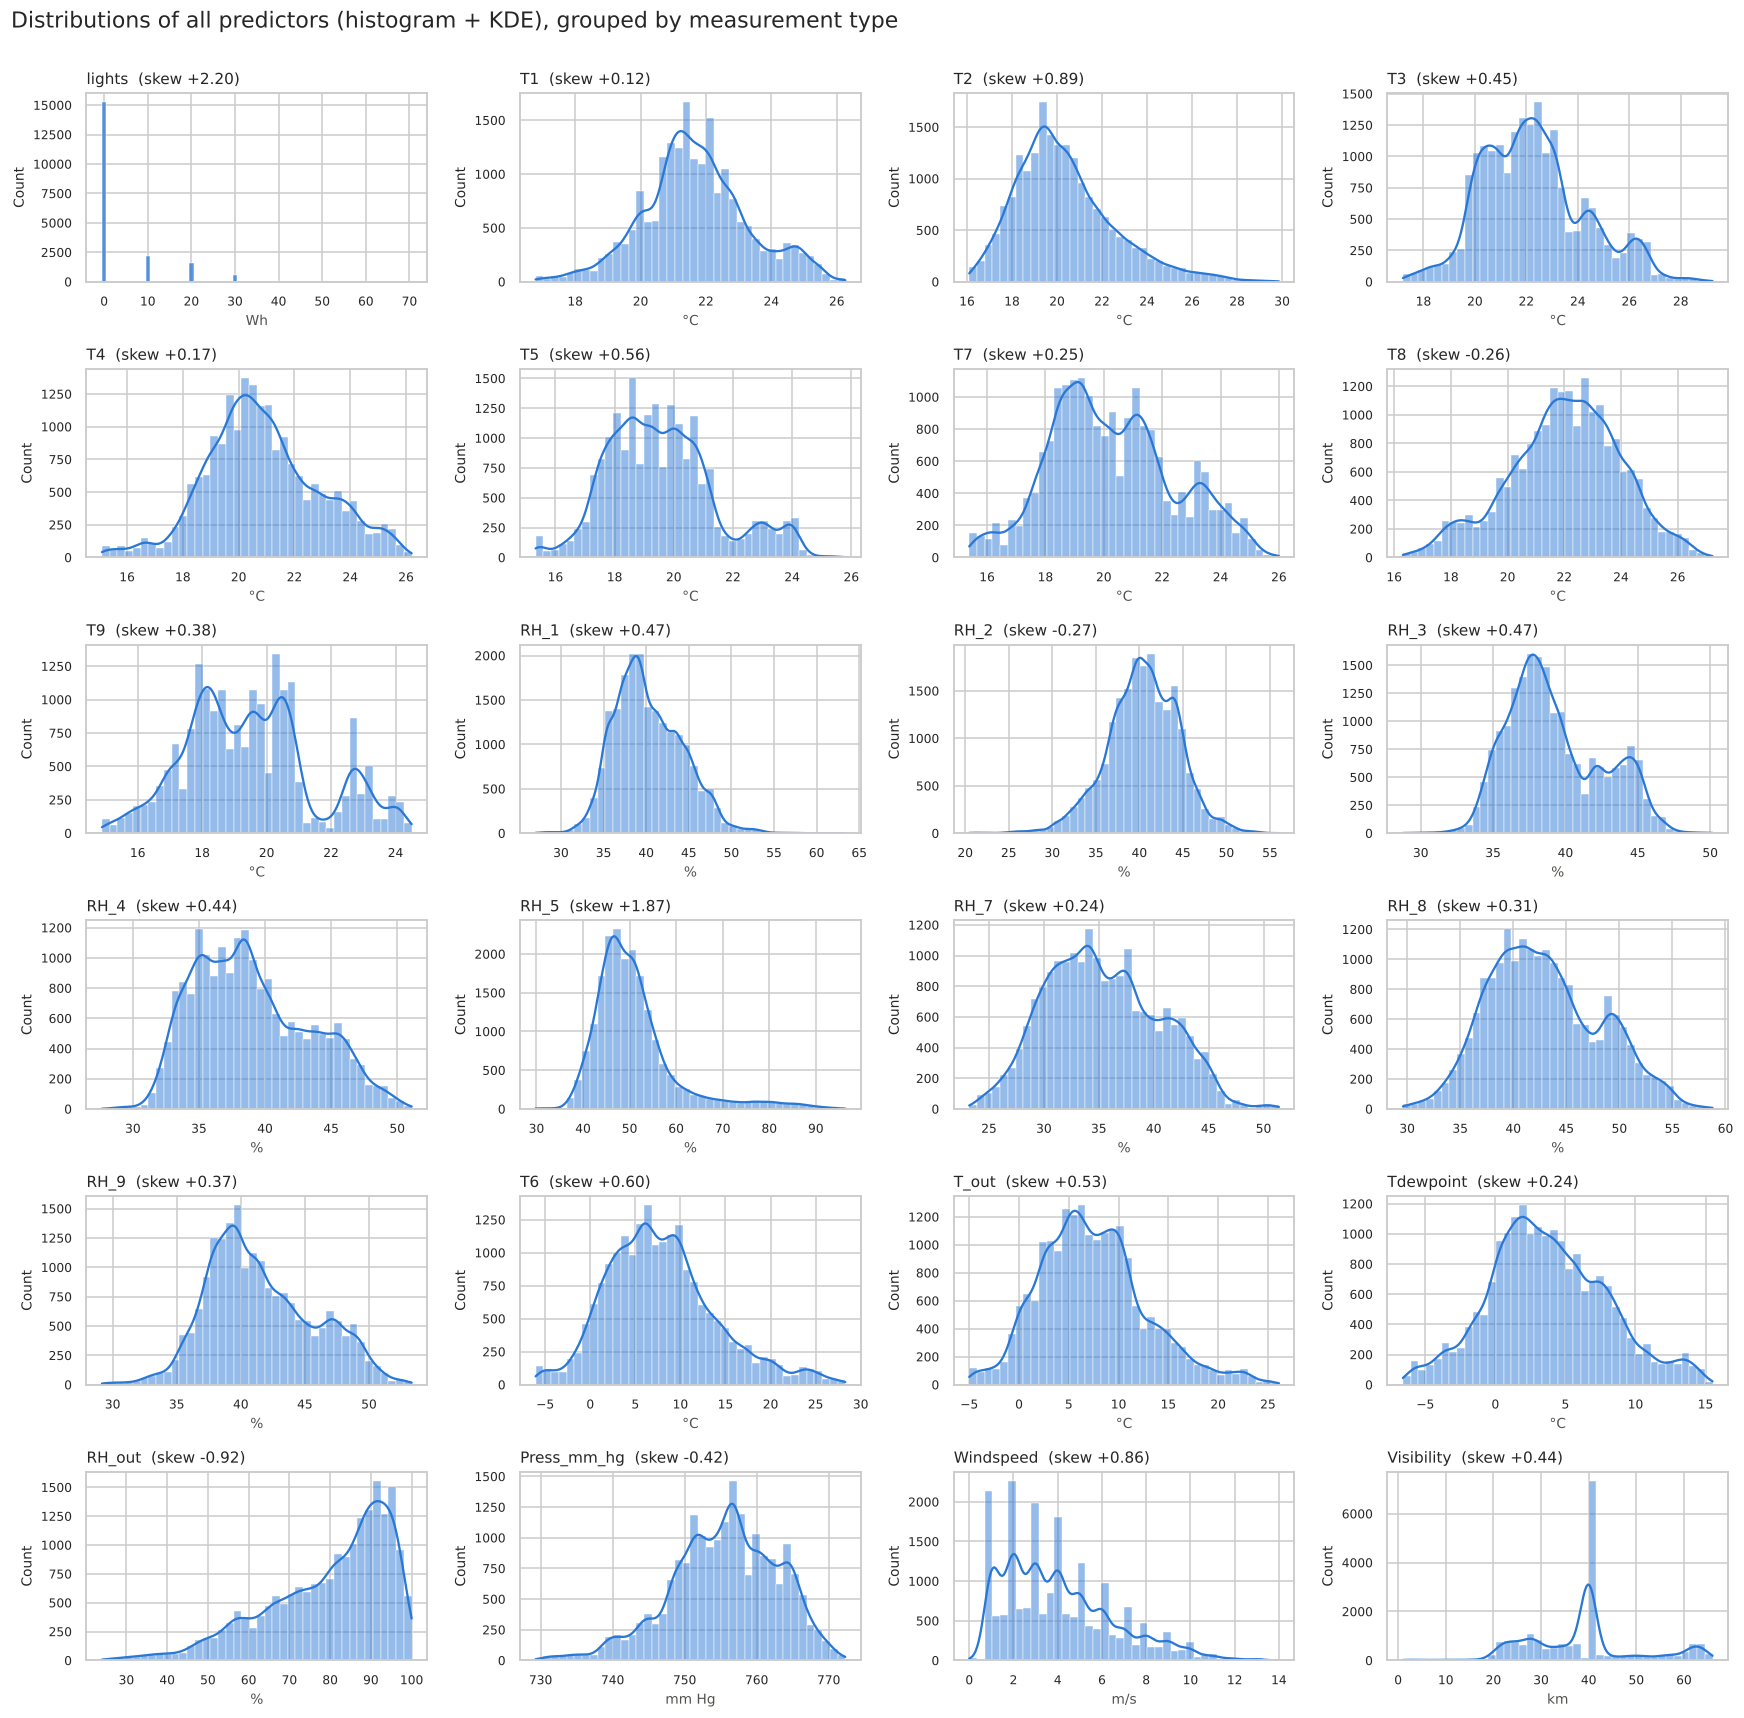

In [28]:
def plot_distribution(ax, series, color=COLOR_MAIN):
    """Histogram + KDE on one axis; discrete bars without KDE when the variable has few distinct values."""
    if series.nunique() <= 10:
        sns.histplot(series, ax=ax, discrete=True, color=color, edgecolor="white", linewidth=0.3)
    else:
        sns.histplot(series, ax=ax, bins=40, kde=True, color=color, edgecolor="white", linewidth=0.3,
                     line_kws={"linewidth": 1.5})
    ax.set_xlabel(UNITS.get(series.name, ""), fontsize=9, color=COLOR_TEXT)
    ax.set_ylabel("Count", fontsize=9)
    ax.tick_params(labelsize=8)


n_cols = 4
n_rows = int(np.ceil(len(PREDICTORS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 2.6 * n_rows))
for ax, col in zip(axes.flat, PREDICTORS):
    plot_distribution(ax, df[col])
    ax.set_title(f"{col}  (skew {df[col].skew():+.2f})", loc="left", fontsize=10)
for ax in axes.flat[len(PREDICTORS):]:
    ax.set_visible(False)
fig.suptitle("Distributions of all predictors (histogram + KDE), grouped by measurement type",
             x=0.01, ha="left", y=1.0)
fig.tight_layout()
save_fig(fig, "task4_all_distributions")
plt.show()

### 4.3 Summary statistics table for all predictors
Besides the standard statistics, the table adds:
- **Skewness** (asymmetry) and **excess kurtosis** (tail weight; 0 for a normal distribution).
- **% zeros**, to detect zero-inflated variables.
- **Bimodality coefficient (BC)** = (skew² + 1) / (kurtosis + 3(n−1)²/((n−2)(n−3))). A BC above 0.555 suggests two peaks. Strong skew also raises BC, so it is only used as a bimodality hint when |skew| < 1, and the plot should confirm it.
- **Shape**: a label from these rules (|skew| < 0.5 = approximately symmetric, 0.5–1 = moderately skewed, ≥ 1 = highly skewed).

> Limitation: skewness and BC summarise the whole distribution in one number, so they miss **several peaks of similar size** (e.g. T9 has |skew| < 0.5 but at least three peaks in 4.2). The plots are needed to confirm every label.

In [29]:
def bimodality_coefficient(series):
    """Sarle's bimodality coefficient from sample skewness and excess kurtosis (no extra libraries needed)."""
    n, g, k = len(series), series.skew(), series.kurt()
    return (g ** 2 + 1) / (k + 3 * (n - 1) ** 2 / ((n - 2) * (n - 3)))


def describe_shape(skew, kurt, pct_zero, bc):
    """Turn shape statistics into a readable label using the thresholds stated above."""
    if pct_zero > 50:
        return "zero-inflated, highly right-skewed" if skew >= 1 else "zero-inflated"
    side = "right" if skew > 0 else "left"
    if abs(skew) < 0.5:
        label = "approximately symmetric"
    elif abs(skew) < 1:
        label = f"moderately {side}-skewed"
    else:
        label = f"highly {side}-skewed"
    if kurt > 3:
        label += ", heavy-tailed"
    if bc > 0.555 and abs(skew) < 1:
        label += ", possibly bimodal"
    return label


stats_table = df[PREDICTORS].describe().T
stats_table.insert(0, "group", predictor_table["group"])
stats_table.insert(1, "unit", predictor_table["unit"])
stats_table["skewness"] = df[PREDICTORS].skew()
stats_table["kurtosis"] = df[PREDICTORS].kurt()
stats_table["pct_zero"] = (df[PREDICTORS] == 0).mean() * 100
stats_table["bimodality_coef"] = [bimodality_coefficient(df[c]) for c in PREDICTORS]
stats_table["shape"] = [
    describe_shape(r.skewness, r.kurtosis, r.pct_zero, r.bimodality_coef) for r in stats_table.itertuples()
]
stats_table = stats_table.drop(columns="count").round(2)
display(stats_table)

print("Predictors by shape:")
for shape, cols in stats_table.groupby("shape").groups.items():
    print(f"  {shape}: {', '.join(cols)}")

,group,unit,mean,std,min,25%,50%,75%,max,skewness,kurtosis,pct_zero,bimodality_coef,shape
lights,Energy (lighting),Wh,3.80,7.94,0.00,0.00,0.00,0.00,70.00,2.20,4.46,77.28,0.78,"zero-inflated, highly right-skewed"
T1,Indoor temperature,°C,21.69,1.61,16.79,20.76,21.60,22.60,26.26,0.12,0.16,0.00,0.32,approximately symmetric
T2,Indoor temperature,°C,20.34,2.19,16.10,18.79,20.00,21.50,29.86,0.89,0.93,0.00,0.46,moderately right-skewed
T3,Indoor temperature,°C,22.27,2.01,17.20,20.79,22.10,23.29,29.24,0.45,-0.01,0.00,0.40,approximately symmetric
T4,Indoor temperature,°C,20.86,2.04,15.10,19.53,20.67,22.10,26.20,0.17,-0.04,0.00,0.35,approximately symmetric
T5,Indoor temperature,°C,19.59,1.84,15.33,18.28,19.39,20.62,25.80,0.56,0.11,0.00,0.42,moderately right-skewed
T7,Indoor temperature,°C,20.27,2.11,15.39,18.70,20.03,21.60,26.00,0.25,-0.46,0.00,0.42,approximately symmetric
T8,Indoor temperature,°C,22.03,1.96,16.31,20.79,22.10,23.39,27.23,-0.26,-0.16,0.00,0.37,approximately symmetric
T9,Indoor temperature,°C,19.49,2.01,14.89,18.00,19.39,20.60,24.50,0.38,-0.32,0.00,0.43,approximately symmetric
RH_1,Indoor humidity,%,40.26,3.98,27.02,37.33,39.66,43.07,63.36,0.47,0.11,0.00,0.39,approximately symmetric


Predictors by shape:
  approximately symmetric: T1, T3, T4, T7, T8, T9, RH_1, RH_2, RH_3, RH_4, RH_7, RH_8, RH_9, Tdewpoint, Press_mm_hg, Visibility
  highly right-skewed, heavy-tailed: RH_5
  moderately left-skewed, possibly bimodal: RH_out
  moderately right-skewed: T2, T5, T6, T_out, Windspeed
  zero-inflated, highly right-skewed: lights


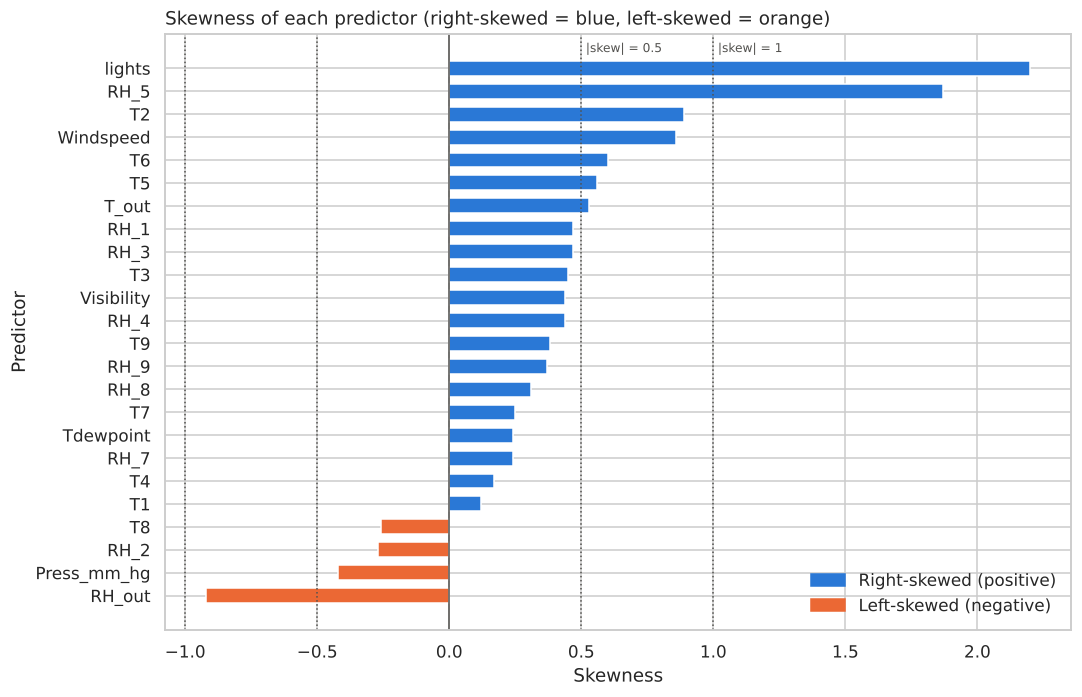

In [30]:
# One-glance summary of asymmetry across all predictors (sorted), with the thresholds used above
skew_sorted = stats_table["skewness"].sort_values()
colors = [COLOR_MAIN if s >= 0 else COLOR_SECOND for s in skew_sorted]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(skew_sorted.index, skew_sorted.values, color=colors, height=0.65)
for x in [-1, -0.5, 0.5, 1]:
    ax.axvline(x, color=COLOR_TEXT, linestyle=":", linewidth=1)
ax.axvline(0, color=COLOR_TEXT, linewidth=1)
for x, text in [(0.5, "|skew| = 0.5"), (1, "|skew| = 1")]:
    ax.annotate(text, xy=(x, 1), xycoords=("data", "axes fraction"), xytext=(3, -12),
                textcoords="offset points", fontsize=8, color=COLOR_TEXT)
ax.set_title("Skewness of each predictor (right-skewed = blue, left-skewed = orange)", loc="left")
ax.set_xlabel("Skewness")
ax.set_ylabel("Predictor")
ax.legend(handles=[Patch(color=COLOR_MAIN, label="Right-skewed (positive)"),
                   Patch(color=COLOR_SECOND, label="Left-skewed (negative)")],
          loc="lower right", frameon=False)
fig.tight_layout()
save_fig(fig, "task4_skewness")
plt.show()

#### 4.3.1 Representative distributions (for the report)
One predictor for each distribution type found above, drawn larger so the shapes are readable in the PDF.

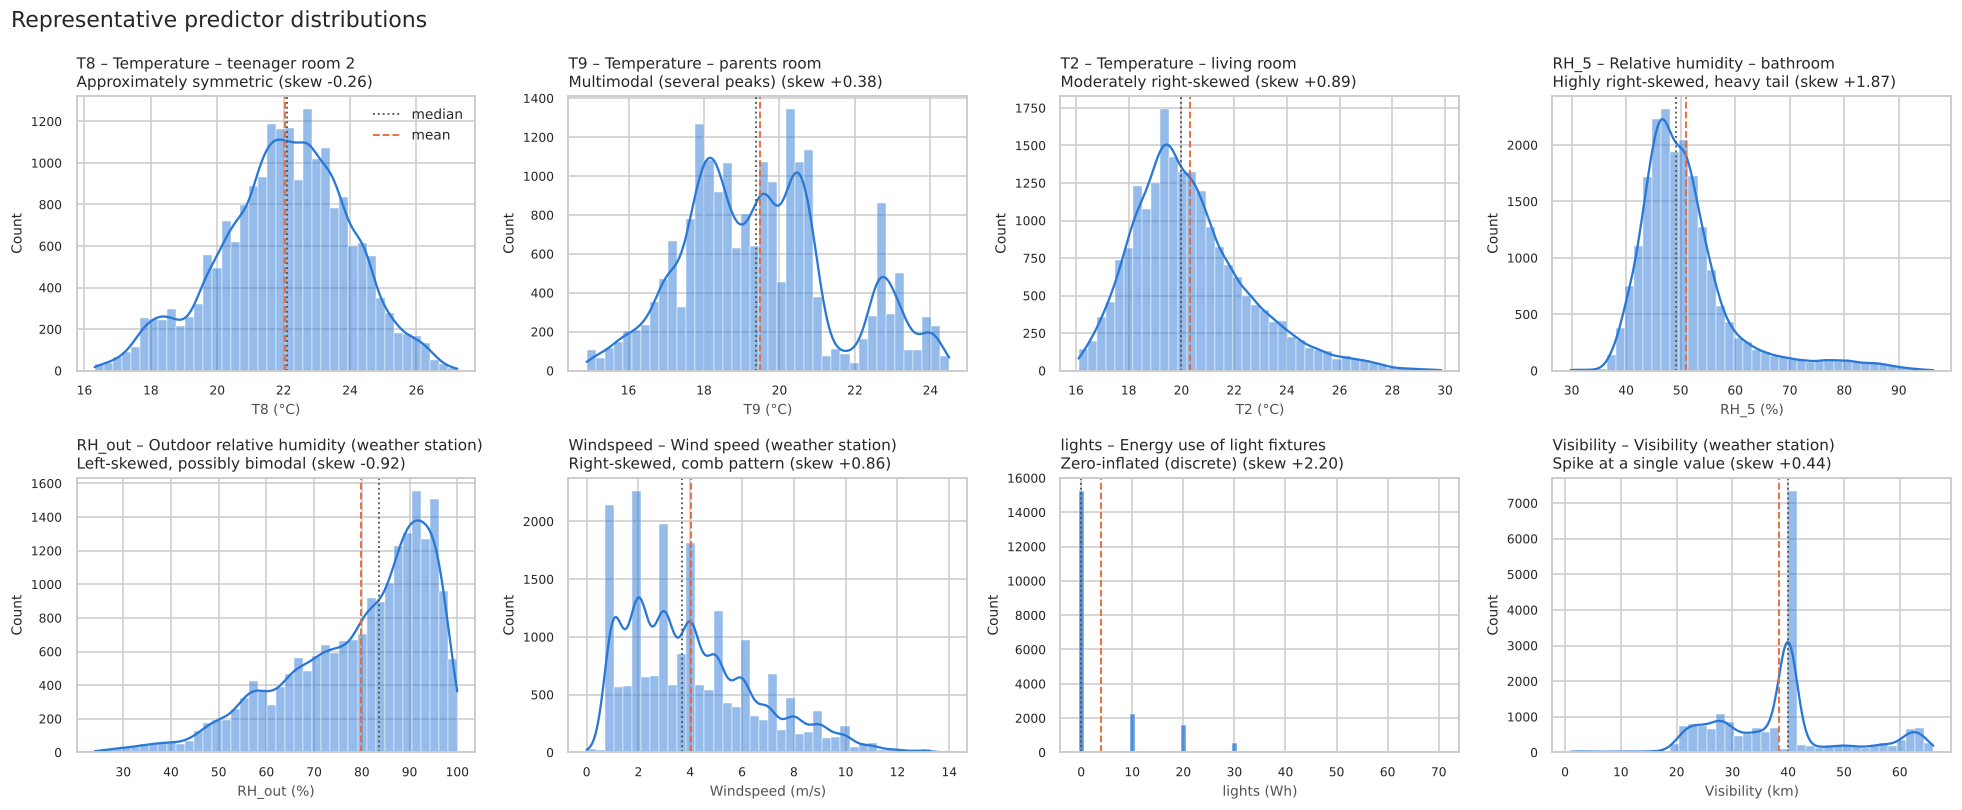

In [31]:
# One example per shape type (chosen from the table above and the plots in 4.2)
REPRESENTATIVE = {
    "T8": "Approximately symmetric",
    "T9": "Multimodal (several peaks)",
    "T2": "Moderately right-skewed",
    "RH_5": "Highly right-skewed, heavy tail",
    "RH_out": "Left-skewed, possibly bimodal",
    "Windspeed": "Right-skewed, comb pattern",
    "lights": "Zero-inflated (discrete)",
    "Visibility": "Spike at a single value",
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, (col, shape_name) in zip(axes.flat, REPRESENTATIVE.items()):
    plot_distribution(ax, df[col])
    ax.axvline(df[col].median(), color=COLOR_TEXT, linestyle=":", linewidth=1.2, label="median")
    ax.axvline(df[col].mean(), color=COLOR_SECOND, linestyle="--", linewidth=1.2, label="mean")
    ax.set_title(f"{col} – {VARIABLES[col][0]}\n{shape_name} (skew {df[col].skew():+.2f})",
                 loc="left", fontsize=10)
    ax.set_xlabel(f"{col} ({UNITS[col]})", fontsize=9)
axes.flat[0].legend(loc="upper right", frameon=False, fontsize=9)
fig.suptitle("Representative predictor distributions", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "task4_representative_distributions")
plt.show()

### 4.4 Task 4 observations

**Overall.** 16 of the 24 predictors are approximately symmetric (|skew| < 0.5): most indoor temperatures and humidities, plus `Tdewpoint`, `Press_mm_hg` and `Visibility`. Five are moderately right-skewed (`T2`, `T5`, `T6`, `T_out`, `Windspeed`), `RH_5` is highly right-skewed with a heavy tail, `RH_out` is left-skewed, and `lights` is zero-inflated. None of the predictors is as skewed as the target (3.39).

**Several peaks in indoor temperatures.** `T9`, `T3`, `T5` and `T7` have low skewness but clearly show two or more peaks, so skewness alone would describe them wrongly. The peaks are explained by the season: the data runs from January to May, and the house warms up as spring arrives (monthly mean `T9`: 16.7 °C in January, 22.4 °C in May). For `T9`, readings below 19 °C come almost entirely from January–March, readings between 19 and 21.5 °C mostly from March–April, and 99% of readings above 21.5 °C from May. The distribution is therefore a mix of seasonal "regimes" rather than one process, which means the data is not stationary over time.

**Physical reasons for the skewed shapes.**
- `T2` (living room): all 539 readings above the IQR upper fence (25.6 °C) occur in May, so the right tail comes from warm late-spring afternoons. `T6` and `T_out` are right-skewed for the same reason (May maximum 26.1 °C outdoors vs 13.1 °C in January).
- `RH_5` (bathroom): readings above 66% are concentrated between 19:00 and 23:00, with a smaller group around 09:00–10:00, and the bathroom is slightly warmer during them (median 20.2 °C vs 19.3 °C). This matches showers, which produce short humidity peaks and therefore a long right tail.
- `RH_out`: outdoor air is close to saturation at night (median 90% between 00:00 and 06:00) and drier in the afternoon (median 67% between 12:00 and 17:00), because relative humidity falls as the air warms. The main peak near 90% comes from humid nights and the smaller bump around 55–60% from dry afternoons. Because humidity cannot exceed 100%, readings pile up just below that limit, which creates the left skew.
- `Windspeed` cannot be negative and has occasional strong-wind periods, which makes it right-skewed. Its comb pattern comes from the weather station: 55% of readings are whole numbers and most of the rest are thirds or sixths, which suggests whole-number hourly readings that were interpolated to 10-minute steps.
- `Visibility`: 36.6% of readings are exactly 40 km, the same spike found in Task 2, so its symmetric skewness hides a very unusual distribution.

**`lights`.** 77% of readings are 0 Wh. Lights are on most often between 18:00 and 22:00 (in 40–49% of readings) and almost never between 02:00 and 04:00 (2–4%), and they are used less as the days get longer (28.5% of readings in January vs 10.9% in May). The variable therefore says more about whether people are at home and awake than about how much energy the lights use, and it might work better as a binary "lights on" feature.

**Implications for modelling.** The predictors use very different units and scales (around 755 mm Hg for pressure vs 0–14 m/s for wind speed), so scale-sensitive models (linear models, k-NN, SVM, neural networks) will need standardisation. `RH_5` and `lights` could be transformed (log/Yeo-Johnson, or a binary indicator), while tree-based models can use them as they are. Because temperatures change steadily from January to May, a random train/test split would let the model see "future" weather conditions during training, so a time-based split should be considered.

## 5. Task 5 – Multivariate Analysis
Relationships between the predictors and the target, and between predictors. All correlations use the **numeric** target (`Appliances` in Wh), not the class label, so no information is lost through binning.

- **Pearson r** measures linear association.
- **Spearman ρ** measures monotonic association on ranks. It is less affected by the skewed target and its outliers.

### 5.1 Correlation heatmap

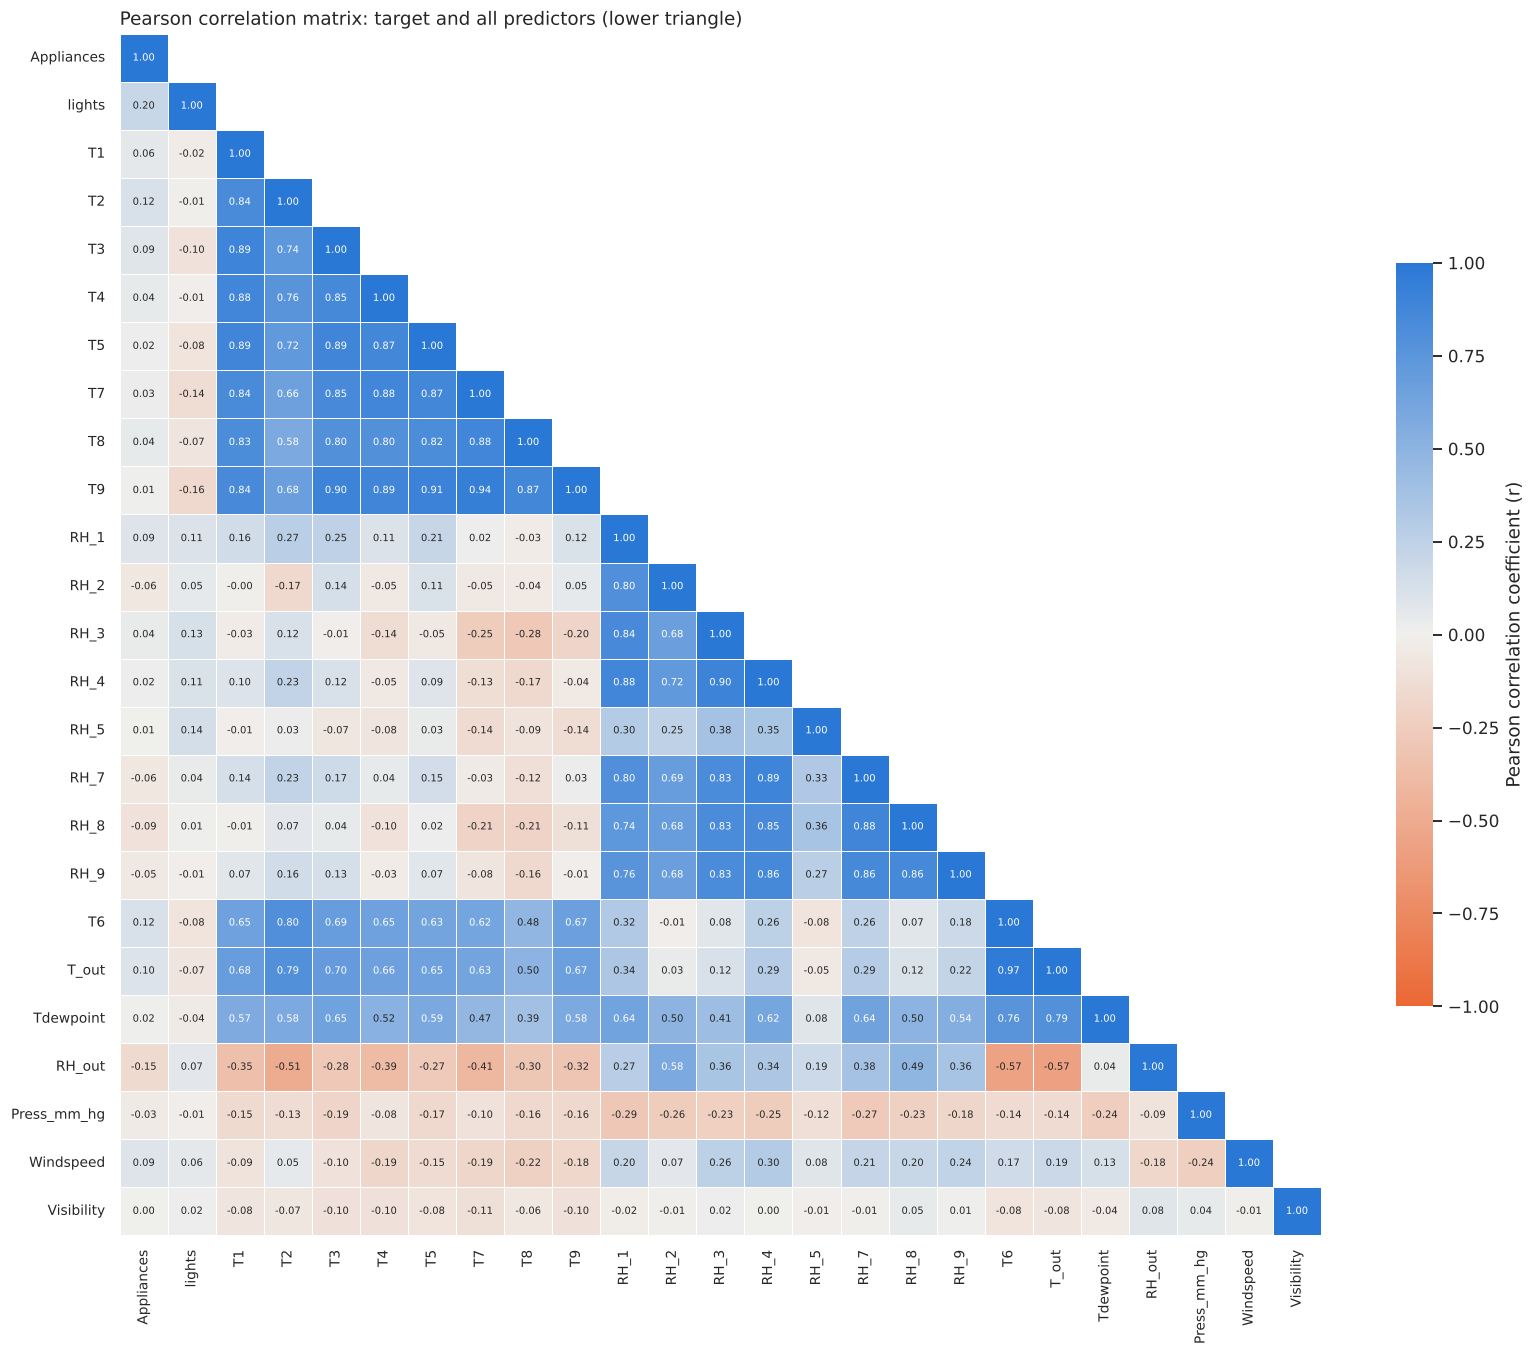

In [32]:
from matplotlib.colors import LinearSegmentedColormap

HEATMAP_COLS = [TARGET] + PREDICTORS            # target first, then predictors grouped as in Task 4
corr_matrix = df[HEATMAP_COLS].corr(method="pearson")

# Diverging colour scale: orange = negative, grey = no correlation, blue = positive
DIVERGING_CMAP = LinearSegmentedColormap.from_list("div", [COLOR_SECOND, "#f0efec", COLOR_MAIN])
mask_upper = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)   # show each pair once

fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(
    corr_matrix, mask=mask_upper, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"fontsize": 6.5}, linewidths=0.4, linecolor="white",
    square=True, cbar_kws={"label": "Pearson correlation coefficient (r)", "shrink": 0.6}, ax=ax,
)
ax.set_title("Pearson correlation matrix: target and all predictors (lower triangle)", loc="left")
ax.tick_params(labelsize=9)
ax.grid(False)   # no background grid behind the empty upper triangle
fig.tight_layout()
save_fig(fig, "task5_correlation_heatmap")
plt.show()

### 5.2 Top 3 features correlated with the target

In [33]:
target_corr = pd.DataFrame({
    "pearson_r": df[PREDICTORS].corrwith(df[TARGET], method="pearson"),
    "spearman_rho": df[PREDICTORS].corrwith(df[TARGET], method="spearman"),
})
target_corr["abs_pearson"] = target_corr["pearson_r"].abs()
target_corr["abs_spearman"] = target_corr["spearman_rho"].abs()
target_corr = target_corr.sort_values("abs_pearson", ascending=False)
display(target_corr.round(3))

top3_pearson = target_corr["abs_pearson"].nlargest(3).index
top3_spearman = target_corr["abs_spearman"].nlargest(3).index
print("Top 3 by |Pearson r|:")
for col in top3_pearson:
    print(f"  {col:<8} r = {target_corr.loc[col, 'pearson_r']:+.3f}   ({VARIABLES[col][0]})")
print("Top 3 by |Spearman rho|:")
for col in top3_spearman:
    print(f"  {col:<8} rho = {target_corr.loc[col, 'spearman_rho']:+.3f}")
print(f"Same three features in both rankings: {set(top3_pearson) == set(top3_spearman)}")
print(f"Strongest |r| of any sensor: {target_corr['abs_pearson'].max():.3f}")

,pearson_r,spearman_rho,abs_pearson,abs_spearman
lights,0.197,0.302,0.197,0.302
RH_out,-0.152,-0.269,0.152,0.269
T2,0.120,0.305,0.120,0.305
T6,0.118,0.242,0.118,0.242
T_out,0.099,0.216,0.099,0.216
RH_8,-0.094,-0.217,0.094,0.217
Windspeed,0.087,0.112,0.087,0.112
RH_1,0.086,0.061,0.086,0.061
T3,0.085,0.217,0.085,0.217
RH_2,-0.060,-0.120,0.060,0.120


Top 3 by |Pearson r|:
  lights   r = +0.197   (Energy use of light fixtures)
  RH_out   r = -0.152   (Outdoor relative humidity (weather station))
  T2       r = +0.120   (Temperature – living room)
Top 3 by |Spearman rho|:
  T2       rho = +0.305
  lights   rho = +0.302
  RH_out   rho = -0.269
Same three features in both rankings: True
Strongest |r| of any sensor: 0.197


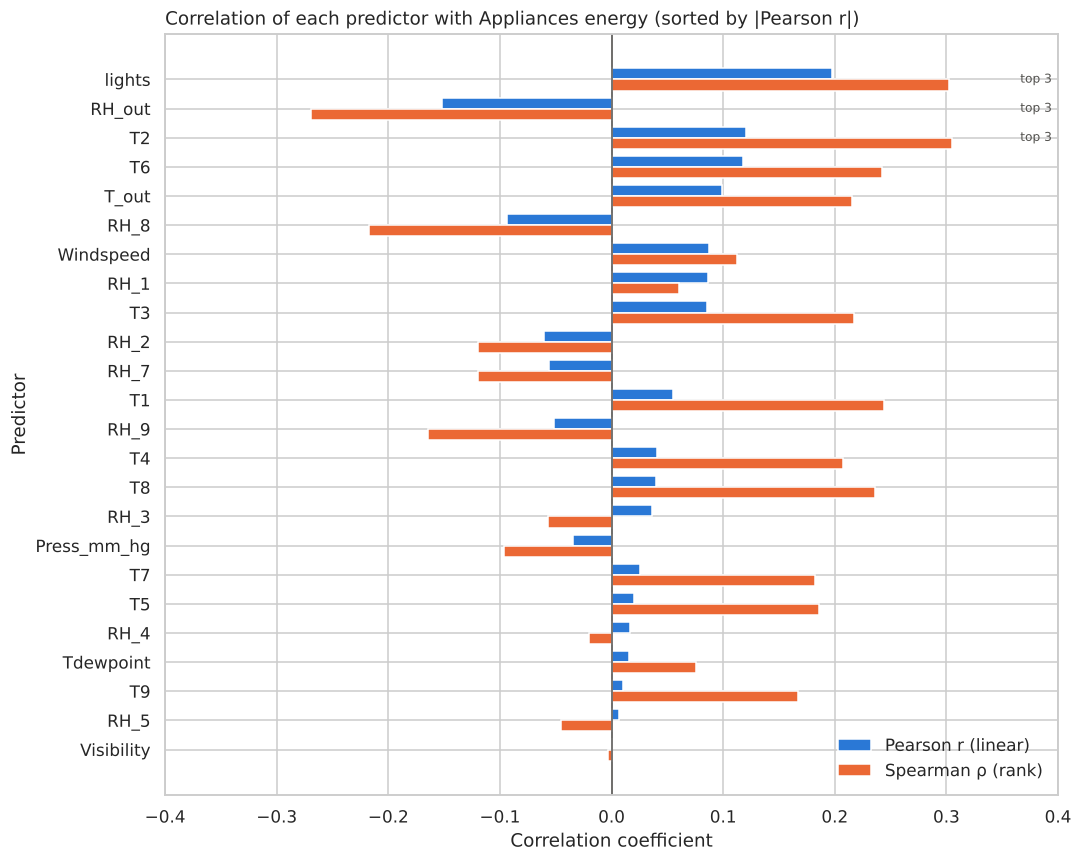

In [34]:
# Pearson vs Spearman for every predictor, sorted by |Pearson|
plot_corr = target_corr.sort_values("abs_pearson")
y_pos = np.arange(len(plot_corr))
bar_h = 0.38

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(y_pos + bar_h / 2, plot_corr["pearson_r"], height=bar_h, color=COLOR_MAIN, label="Pearson r (linear)")
ax.barh(y_pos - bar_h / 2, plot_corr["spearman_rho"], height=bar_h, color=COLOR_SECOND, label="Spearman ρ (rank)")
ax.axvline(0, color=COLOR_TEXT, linewidth=1)
ax.set_yticks(y_pos, plot_corr.index)
ax.set_xlim(-0.4, 0.4)
ax.set_title("Correlation of each predictor with Appliances energy (sorted by |Pearson r|)", loc="left")
ax.set_xlabel("Correlation coefficient")
ax.set_ylabel("Predictor")
ax.legend(loc="lower right", frameon=False)
# Mark the top 3 by |Pearson r|
for i, col in enumerate(plot_corr.index):
    if col in top3_pearson:
        ax.annotate("top 3", xy=(0.4, i), xytext=(-4, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=8, color=COLOR_TEXT)
fig.tight_layout()
save_fig(fig, "task5_target_correlations")
plt.show()

#### 5.2.1 Time of day vs the sensor predictors
Task 3 showed a strong daily pattern in the target. Hour of day is a cyclic variable with a non-linear effect (low at night, peak around 18:00), so Pearson r understates it. The **correlation ratio η** measures how much of the target's variance is explained by group means (here: the mean for each hour). η ranges from 0 to 1 and equals |r| when the relationship is linear, so it can be compared with the correlations above.

In [35]:
def correlation_ratio(groups, values):
    """Correlation ratio (eta): share of the variance of `values` explained by the mean of each group."""
    overall_mean = values.mean()
    group_stats = values.groupby(groups).agg(["size", "mean"])
    between = (group_stats["size"] * (group_stats["mean"] - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between / total)


time_features = {
    "hour of day": df["date"].dt.hour,
    "day of week": df["date"].dt.dayofweek,
    "month": df["date"].dt.month,
}
time_effects = pd.DataFrame({
    "eta (correlation ratio)": {name: correlation_ratio(g, df[TARGET]) for name, g in time_features.items()},
    "pearson_r (treating it as a number)": {name: g.corr(df[TARGET]) for name, g in time_features.items()},
}).round(3)
display(time_effects)
print(f"Strongest sensor |r| for comparison: {target_corr['abs_pearson'].max():.3f} ({target_corr['abs_pearson'].idxmax()})")

,eta (correlation ratio),pearson_r (treating it as a number)
hour of day,0.387,0.217
day of week,0.086,0.003
month,0.022,-0.012


Strongest sensor |r| for comparison: 0.197 (lights)


Do the strongest sensor correlations survive once the daily cycle is removed? Below, each hour's mean is subtracted from both the feature and the target, and the remaining variation is correlated. A feature that only mirrors the time of day drops to about 0; a feature that carries its own information keeps part of its correlation.

In [36]:
hour = df["date"].dt.hour


def remove_hour_mean(series):
    """Subtract the mean of each hour of day, leaving only the variation within the same hour."""
    return series - series.groupby(hour).transform("mean")


check_cols = target_corr.index[:5]   # the five strongest |Pearson r|
within_hour = pd.DataFrame({
    "pearson_r": target_corr.loc[check_cols, "pearson_r"],
    "within_hour_r": [remove_hour_mean(df[c]).corr(remove_hour_mean(df[TARGET])) for c in check_cols],
    "eta_feature_vs_hour": [correlation_ratio(hour, df[c]) for c in check_cols],   # how strongly the feature itself follows the clock
}, index=check_cols).round(3)
display(within_hour)

,pearson_r,within_hour_r,eta_feature_vs_hour
lights,0.197,0.144,0.322
RH_out,-0.152,0.029,0.588
T2,0.120,0.022,0.365
T6,0.118,-0.010,0.416
T_out,0.099,-0.013,0.365


### 5.3 Multicollinearity
Two complementary checks:
- **Pairwise:** predictor pairs with |r| ≥ 0.8 are treated as strongly collinear.
- **Variance Inflation Factor (VIF):** how well each predictor is explained by *all* the others together. VIF > 10 is the usual sign of severe multicollinearity. It is computed as the diagonal of the inverse of the predictor correlation matrix, so no extra library is needed.

In [37]:
COLLINEAR_THRESHOLD = 0.8

pred_corr = df[PREDICTORS].corr()
collinear_pairs = pd.DataFrame(
    [(a, b, pred_corr.loc[a, b])
     for i, a in enumerate(PREDICTORS) for b in PREDICTORS[i + 1:]
     if abs(pred_corr.loc[a, b]) >= COLLINEAR_THRESHOLD],
    columns=["predictor_1", "predictor_2", "pearson_r"],
).sort_values("pearson_r", key=abs, ascending=False, ignore_index=True)
collinear_pairs["pearson_r"] = collinear_pairs["pearson_r"].round(3)

print(f"Pairs with |r| >= {COLLINEAR_THRESHOLD}: {len(collinear_pairs)} "
      f"(of which |r| >= 0.9: {(collinear_pairs['pearson_r'].abs() >= 0.9).sum()})")
display(collinear_pairs)

# Average correlation inside each predictor group (how much the rooms move together)
group_corr = {}
for group, cols in PREDICTOR_GROUPS.items():
    if len(cols) > 1:
        values = pred_corr.loc[cols, cols].values[np.triu_indices(len(cols), k=1)]
        group_corr[group] = {"mean_r": values.mean(), "min_r": values.min(), "max_r": values.max()}
display(pd.DataFrame(group_corr).T.round(2))

Pairs with |r| >= 0.8: 35 (of which |r| >= 0.9: 4)


,predictor_1,predictor_2,pearson_r
0,T6,T_out,0.975
1,T7,T9,0.945
2,T5,T9,0.911
3,T3,T9,0.901
4,RH_3,RH_4,0.899
5,RH_4,RH_7,0.894
6,T1,T3,0.892
7,T4,T9,0.889
8,T3,T5,0.888
9,T1,T5,0.885


,mean_r,min_r,max_r
Indoor temperature,0.83,0.58,0.94
Indoor humidity,0.68,0.25,0.90
Outdoor – weather station,-0.02,-0.57,0.79


In [38]:
# VIF_j = j-th diagonal element of the inverse correlation matrix
vif = pd.Series(np.diag(np.linalg.inv(pred_corr.values)), index=PREDICTORS, name="VIF").sort_values(ascending=False)
vif_table = vif.to_frame()
vif_table["group"] = predictor_table.loc[vif.index, "group"]
vif_table["severity"] = pd.cut(vif, bins=[0, 5, 10, np.inf], labels=["low (< 5)", "moderate (5–10)", "severe (> 10)"])
display(vif_table.round(1))
print(vif_table["severity"].value_counts().sort_index().to_string())

,VIF,group,severity
T_out,135.0,Outdoor – weather station,severe (> 10)
Tdewpoint,81.4,Outdoor – weather station,severe (> 10)
RH_out,42.7,Outdoor – weather station,severe (> 10)
T6,30.2,Outdoor – wall sensor,severe (> 10)
T2,28.8,Indoor temperature,severe (> 10)
T9,27.9,Indoor temperature,severe (> 10)
RH_2,21.9,Indoor humidity,severe (> 10)
T1,19.6,Indoor temperature,severe (> 10)
T7,17.5,Indoor temperature,severe (> 10)
RH_4,17.0,Indoor humidity,severe (> 10)


severity
low (< 5)           5
moderate (5–10)     5
severe (> 10)      14


`Tdewpoint` has one of the highest VIFs. Dew point is physically determined by air temperature and relative humidity, so the check below measures how much of `Tdewpoint` is reproduced by `T_out` and `RH_out` alone (least-squares fit; R² = 1 means fully redundant).

In [39]:
def r_squared(y, X):
    """R² of an ordinary least-squares fit of y on the columns of X (an intercept is added)."""
    X = np.column_stack([np.ones(len(y))] + list(X))
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    residual = y - X @ coef
    return 1 - (residual ** 2).sum() / ((y - y.mean()) ** 2).sum()


t_out, rh_out = df["T_out"], df["RH_out"]
print(f"R² of Tdewpoint from T_out and RH_out (linear terms):               {r_squared(df['Tdewpoint'], [t_out, rh_out]):.3f}")
print(f"R² of Tdewpoint from T_out and RH_out (+ T_out×RH_out, log RH_out):  "
      f"{r_squared(df['Tdewpoint'], [t_out, rh_out, t_out * rh_out, np.log(rh_out)]):.3f}")

R² of Tdewpoint from T_out and RH_out (linear terms):               0.984
R² of Tdewpoint from T_out and RH_out (+ T_out×RH_out, log RH_out):  1.000


### 5.4 Pairplot of key features
The top 3 predictors (`lights`, `RH_out`, `T2`) plus the two outdoor temperatures (`T_out`, `T6`), the most collinear pair found in 5.3. Points are coloured by the target class from Task 3, to show how well these features separate Low, Medium and High consumption. A random sample of 3,000 readings keeps the plot readable (fixed `random_state` for reproducibility).

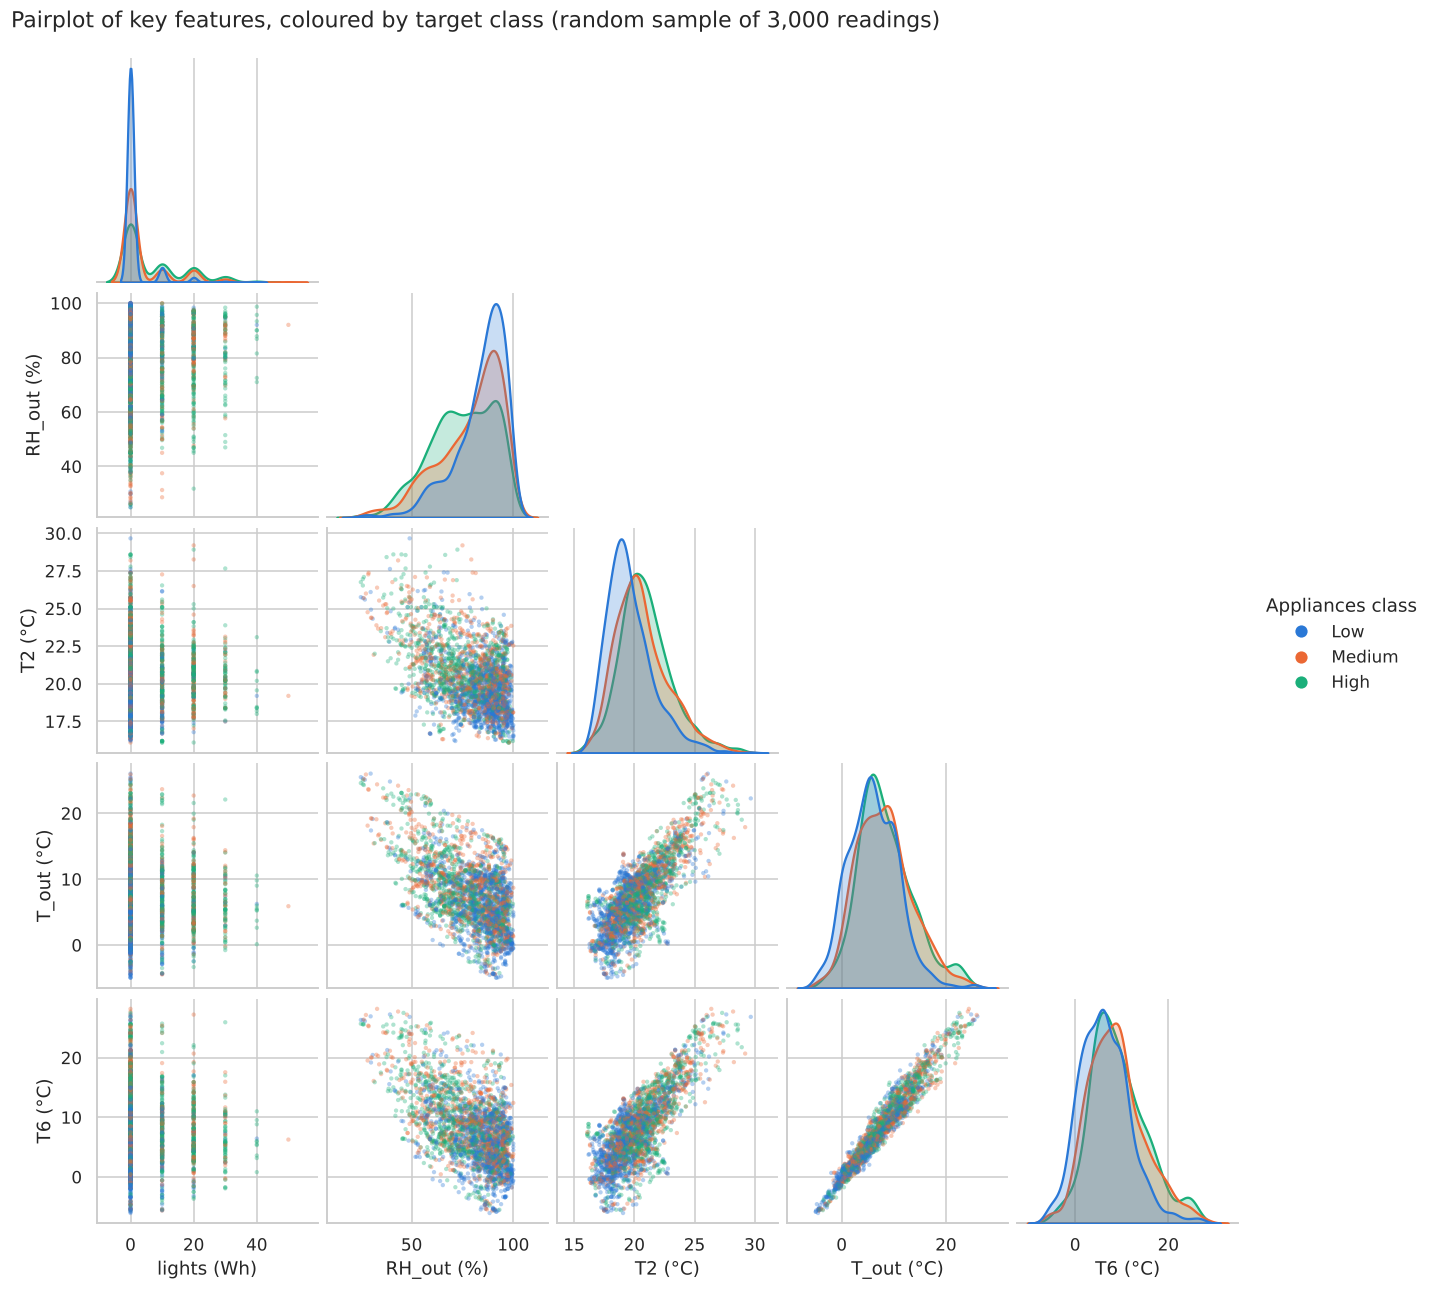

In [40]:
PAIRPLOT_COLS = ["lights", "RH_out", "T2", "T_out", "T6"]
CLASS_PALETTE = {"Low": COLOR_MAIN, "Medium": COLOR_SECOND, "High": "#1baf7a"}   # blue, orange, aqua

pair_sample = df[PAIRPLOT_COLS + [CLASS_COL]].sample(n=3000, random_state=RANDOM_STATE)
grid = sns.pairplot(
    pair_sample, vars=PAIRPLOT_COLS, hue=CLASS_COL, hue_order=CLASS_LABELS, palette=CLASS_PALETTE,
    corner=True, height=2.3, diag_kind="kde",
    plot_kws={"s": 8, "alpha": 0.35, "linewidth": 0}, diag_kws={"common_norm": False, "linewidth": 1.5},
)
# Units on the axis labels
for ax in grid.axes.flat:
    if ax is None:
        continue
    if ax.get_xlabel():
        ax.set_xlabel(f"{ax.get_xlabel()} ({UNITS[ax.get_xlabel()]})")
    if ax.get_ylabel():
        ax.set_ylabel(f"{ax.get_ylabel()} ({UNITS[ax.get_ylabel()]})")
grid._legend.set_title("Appliances class")
for handle in grid._legend.legend_handles:   # larger, solid legend markers (the points themselves are faint)
    handle.set_alpha(1)
    if hasattr(handle, "set_markersize"):
        handle.set_markersize(8)
    else:
        handle.set_sizes([60])
grid.figure.suptitle("Pairplot of key features, coloured by target class (random sample of 3,000 readings)",
                     x=0.01, ha="left", y=1.02)
save_fig(grid.figure, "task5_pairplot")
plt.show()

In [41]:
# Class-wise medians: a numeric check of what the pairplot shows
display(df.groupby(CLASS_COL, observed=False)[PAIRPLOT_COLS].median().round(2))
print("Share of readings with lights on, by class (%):")
print((df.groupby(CLASS_COL, observed=False)["lights"].apply(lambda s: (s > 0).mean() * 100)).round(1).to_string())

,lights,RH_out,T2,T_out,T6
Appliances_class,,,,,
Low,0.0,88.0,19.23,5.67,5.76
Medium,0.0,84.0,20.23,7.60,8.00
High,0.0,76.0,20.60,7.90,8.63


Share of readings with lights on, by class (%):
Appliances_class
Low        8.9
Medium    23.4
High      38.7


### 5.5 Task 5 observations

**Top 3 features.** By |Pearson r|, the three predictors most correlated with appliance energy are `lights` (r = +0.197), `RH_out` (r = −0.152) and `T2` (r = +0.120). Spearman ranks the same three features first (ρ = +0.302, −0.269 and +0.305). All of these correlations are weak: no single sensor explains more than about 4% of the target's variance (0.197² ≈ 0.04). The directions make sense: more energy is used when the lights are on, when the living room is warmer and when the outdoor air is drier.

**Pearson vs Spearman.** For most temperatures Spearman is much larger than Pearson (e.g. `T1`: ρ = 0.244 vs r = 0.055). Pearson measures straight-line association and is dominated by the strongly skewed target, whose largest readings occur at many different temperatures. Spearman works on ranks, so it captures the consistent but non-linear (monotonic) trend that higher temperatures go with higher consumption.

**Time of day.** Hour of day has η = 0.387, about twice the strongest sensor correlation, while day of week (η = 0.086) and month (η = 0.022) matter little. The top features themselves follow the daily cycle: once each hour's mean is removed from both the feature and the target, the correlation of `RH_out` falls from −0.152 to 0.029 and that of `T2` from 0.120 to 0.022 (`T6` and `T_out` fall to about 0). These variables are therefore mainly proxies for the time of day: the outdoor air is driest and the living room warmest in the afternoon and evening, which is also when the household is active. `lights` keeps most of its correlation (0.197 → 0.144), so it carries information about occupancy that the clock alone does not.

**Multicollinearity.** 35 predictor pairs have |r| ≥ 0.8, and 14 of the 24 predictors have VIF > 10. Three groups move together:
- **Indoor temperatures** (mean r = 0.83 between rooms, up to 0.945 for `T7`–`T9`): all rooms share the same heating system and the same outdoor conditions.
- **Indoor humidities** (mean r = 0.68, up to 0.90 for `RH_3`–`RH_4`): moisture spreads through the house; only the bathroom (`RH_5`) behaves differently.
- **Outdoor temperature:** `T6` and `T_out` (r = 0.975) measure almost the same quantity at two locations.

`Tdewpoint` has a VIF of 81 because it is not an independent measurement: dew point is a physical function of air temperature and relative humidity, and `T_out` and `RH_out` reproduce it almost exactly (R² ≈ 1.00). `T_out` has the highest VIF (135) because it is explained by `T6`, `Tdewpoint` and `RH_out` together.

**Patterns in the pairplot.** `T6` vs `T_out` is a tight straight line. `T2` rises roughly linearly with outdoor temperature (r = 0.79 with `T_out`). `RH_out` falls as `T_out` rises (r = −0.57), with a curved, fan-shaped spread, because relative humidity depends on temperature non-linearly. `lights` takes only a few discrete values. The three target classes overlap almost completely in every panel. The clearest difference is in `lights`: the lights are on in 8.9% of Low readings vs 38.7% of High readings, but 61% of High readings still have the lights off.

**Implications for modelling.** No single sensor separates the classes, so a linear model on the raw sensors is unlikely to perform well. Better options are non-linear models (e.g. tree ensembles) combined with engineered time features (hour of day, possibly encoded with sine and cosine because it is cyclic). Redundant predictors should be reduced before fitting linear or distance-based models: drop one of each near-duplicate (e.g. `T6` or `T_out`, and `Tdewpoint`), average the indoor temperature and humidity sensors, or use PCA.

## 6. Initial Insights for Modelling
*(Report Section 5 — written only, not implemented.)*

- **Most promising features:**
  - *Hour of day* (engineered from `date`): the strongest single driver found (η = 0.387, about twice the best sensor).
  - *`lights`*: the strongest sensor (r = 0.197) and the only one that keeps most of its correlation within the same hour (0.144), i.e. a direct occupancy signal.
  - *Recent consumption*: the target is strongly autocorrelated (0.75 with the reading 10 minutes earlier, 0.22 with the same time on the previous day), so lagged values would be powerful if the task is short-term forecasting.
  - *Activity-related room sensors*: living room `T2`, kitchen `RH_1`, laundry `T3` and bathroom `RH_5`, which react to what occupants do. The original study (Candanedo et al., 2017) also ranked these room sensors highest.
  - Outdoor variables (`T_out`, `RH_out`) add context but mostly repeat the time-of-day information.
- **Preprocessing needed** (scaling, encoding, feature selection):
  - *Feature engineering:* hour of day encoded with sine and cosine (so that 23:00 and 00:00 are close), a weekend flag, a binary "lights on" flag, and optionally lagged or rolling consumption.
  - *Scaling:* standardisation, fitted on the training set only, for scale-sensitive models (logistic regression, SVM, k-NN, neural networks), because the ranges differ widely (about 755 mm Hg for pressure vs 0–14 m/s for wind speed). Tree-based models do not need it.
  - *Transformations:* log or Yeo-Johnson for the skewed `RH_5`; a log transform of the target only if it is modelled as regression.
  - *Encoding:* all predictors are numeric, so no one-hot encoding is required. The target classes are ordinal and can be encoded as Low = 0, Medium = 1, High = 2.
  - *Feature selection:* remove redundant predictors — `Tdewpoint` (R² ≈ 1.00 from `T_out` and `RH_out`) and one of `T6`/`T_out` (r = 0.975) — and summarise the indoor temperature and humidity groups (room averages or PCA) to bring the VIFs below 10. `rv1`, `rv2` and the faulty `RH_6` are already removed.
  - *Data splitting:* split by time (e.g. train on January–April and test on May, or use `TimeSeriesSplit`) rather than at random. Neighbouring 10-minute readings are almost identical and the data drifts with the season, so a random split would overestimate accuracy.
- **Modelling approaches that might work well:**
  - *Tree ensembles* (Random Forest, gradient boosting such as XGBoost or LightGBM) are the best first choice: they capture the non-linear time-of-day effect and interactions, need no scaling and cope with collinear inputs. A gradient boosting model was also the best model in the original study.
  - *Multinomial (or ordinal) logistic regression* as an interpretable baseline, after scaling and removing collinear features.
  - *Sequence models* (lag-feature models, or LSTM/GRU networks) if past consumption is allowed as an input.
  - Because the classes are ordinal and not perfectly balanced, evaluation should use macro-F1 or balanced accuracy together with a confusion matrix (confusing Low with High is worse than confusing Low with Medium).

## 7. Task 6 – Engineering Interpretation

Supporting calculations used in the answers below.

In [42]:
# How appliance energy is distributed over the target classes
energy_by_class = df.groupby(CLASS_COL, observed=False)[TARGET].agg(readings="size", energy_Wh="sum")
energy_by_class["pct_readings"] = energy_by_class["readings"] / len(df) * 100
energy_by_class["pct_energy"] = energy_by_class["energy_Wh"] / df[TARGET].sum() * 100
display(energy_by_class.round(1))

top10_share = df[TARGET].nlargest(int(len(df) * 0.10)).sum() / df[TARGET].sum() * 100
daily_kwh = df.groupby(df["date"].dt.date)[TARGET].sum() / 1000
is_weekend = df["date"].dt.dayofweek >= 5
print(f"Share of appliance energy used in the top 10% of readings: {top10_share:.1f}%")
print(f"Daily appliance energy: mean {daily_kwh.mean():.1f} kWh (min {daily_kwh.min():.1f}, max {daily_kwh.max():.1f})")
print(f"Mean Appliances per 10 min: weekdays {df.loc[~is_weekend, TARGET].mean():.1f} Wh, "
      f"weekends {df.loc[is_weekend, TARGET].mean():.1f} Wh")
print(f"Lighting share of (appliances + lighting) energy: "
      f"{df['lights'].sum() / (df['lights'].sum() + df[TARGET].sum()) * 100:.1f}%")

# How strongly each variable is tied to the calendar day (eta close to 1 = almost constant within a day)
calendar_day = df["date"].dt.date
day_eta = pd.Series(
    {c: correlation_ratio(calendar_day, df[c]) for c in ["Press_mm_hg", "T_out", "Windspeed", "RH_out", "lights", TARGET]},
    name="eta_with_calendar_day",
).round(3)
display(day_eta.to_frame())

# Persistence of consumption: correlation of the target with its own past values (rows are in time order)
lags = {"10 min": 1, "30 min": 3, "1 hour": 6, "24 hours": 144}
display(pd.Series({name: df[TARGET].autocorr(lag) for name, lag in lags.items()},
                  name="autocorrelation").round(3).to_frame())

,readings,energy_Wh,pct_readings,pct_energy
Appliances_class,,,,
Low,7462,327800,37.8,17.0
Medium,6047,402520,30.6,20.9
High,6226,1197690,31.5,62.1


Share of appliance energy used in the top 10% of readings: 37.1%
Daily appliance energy: mean 14.0 kWh (min 5.4, max 27.1)
Mean Appliances per 10 min: weekdays 96.6 Wh, weekends 100.6 Wh
Lighting share of (appliances + lighting) energy: 3.7%


,eta_with_calendar_day
Press_mm_hg,0.966
T_out,0.868
Windspeed,0.793
RH_out,0.604
lights,0.425
Appliances,0.295


,autocorrelation
10 min,0.753
30 min,0.438
1 hour,0.324
24 hours,0.217


1. **What do the correlations mean in engineering terms?**
   The `Appliances` meter only measures plug loads (kitchen appliances, washing machine, electronics, etc.); heating, the hot-water heat pump, the ventilation unit and lighting are metered separately (Candanedo et al., 2017). The target is therefore driven by what the occupants do, not by the thermal physics of the building, which explains why every sensor correlation is weak (|r| ≤ 0.197, i.e. at most about 4% of the variance). The sensors act as indirect "soft sensors" of occupant activity: the lights are switched on when people are at home and awake, the living room warms up when it is occupied and while cooking, and kitchen and bathroom humidity rise with cooking and showers. The outdoor correlations (`RH_out`, `T_out`) are mostly a side-effect of the daily cycle: removing each hour's mean reduces them to about 0, whereas `lights` keeps r = 0.144. In AIoT terms, the value of this sensor network for predicting appliance energy lies in detecting occupancy, not in measuring the thermal state of the house.

2. **Are there any unexpected patterns from an engineering perspective?**
   - *Temperature barely matters.* In most houses energy use follows the outdoor temperature through heating. Here it does not, because heating is not part of the target and the house is built to passive-house standard, so indoor temperatures are buffered (about 15–30 °C indoors while outdoors ranges from −5 to 26 °C).
   - *A faulty sensor in a published dataset.* RH_6 drifted from a monthly mean of 92% to 21% while the weather station stayed above 70%, and it stuck at 1% and 99.9%. The original paper does not report this.
   - *Atmospheric pressure.* Pressure has almost no correlation with the target (r = −0.035), yet the authors' gradient boosting model ranked it the second most important variable. Pressure changes slowly: it is almost constant within a day and different between days (η with the calendar day = 0.966), so a tree model can use it to recognise *which day* a reading belongs to rather than as a physical cause. This is a likely reason for the large gap between their training (R² = 0.97) and testing (R² = 0.57) results.
   - *Weekends look like weekdays* (mean 96.6 vs 100.6 Wh per 10 minutes), which fits a household where one adult works from home.
   - *Wind speed's comb pattern* comes from hourly weather data that were linearly interpolated to 10-minute steps (confirmed in the paper), so the weather variables are smoother than real 10-minute measurements.

3. **What physical/process relationships do the data reflect?**
   - *Daily occupancy cycle:* a base load of about 50 Wh per 10 minutes (≈300 W: fridge, standby devices, network equipment) at night, rising in the morning, with an evening peak at 17:00–20:00 (median 100–120 Wh) linked to cooking. Consumption persists over short periods (autocorrelation 0.75 at 10 minutes) and repeats daily (0.22 at 24 hours).
   - *Peak loads dominate the energy:* the High class contains 31.5% of readings but 62.1% of the appliance energy, and the top 10% of readings alone account for 37.1%. Predicting peaks is therefore what matters for demand response or peak shaving.
   - *Heat transfer in an airtight, well-insulated building:* indoor temperatures move together (mean r = 0.83 between rooms), and the house warms from January to May with the outdoor temperature and solar gains (`T2` vs `T_out`: r = 0.79). This seasonal warming creates the multimodal temperature distributions.
   - *Moisture transport and psychrometrics:* humidity spreads between rooms (mean r = 0.68) except in the bathroom, where showers create local peaks. Relative humidity falls as air warms (`RH_out` vs `T_out`: r = −0.57), and dew point is fully determined by temperature and relative humidity (R² ≈ 1.00).

4. **Based on your engineering knowledge, are there any missing features that would be important?**
   - *Occupancy:* number of people at home, motion (PIR) or door sensors, or CO₂ concentration as an occupancy proxy. These would measure the main driver directly instead of indirectly through lights and humidity.
   - *Appliance-level sub-metering* (smart plugs on the oven, washing machine, dishwasher), which would show which device causes each peak.
   - *Calendar information:* public and school holidays and the home-office schedule.
   - *On-site solar irradiance or cloud cover*, which drives indoor temperatures and lighting needs and is not provided by the weather station about 12 km away.
   - *Heating and hot-water state:* wood-stove use, baseboard heaters and heat-pump operation.
   - *Past consumption:* lagged and rolling values of the target are not included as features but are strongly predictive (autocorrelation 0.75).

*Reference: Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). Data driven prediction models of energy use of appliances in a low-energy house. Energy and Buildings, 140, 81–97. https://doi.org/10.1016/j.enbuild.2017.01.083*

## 8. Task 7 – Challenges Encountered

- **A "clean" dataset that was not clean.** The data has no missing values and no duplicated rows, so the standard checks suggested no problems. The RH_6 sensor fault was only found by comparing the sensor with an independent measurement of the same quantity (the weather station) and by checking for readings stuck at the sensor limits. Deciding how to handle it was also difficult: interpolating the clipped readings would not fix the drift, so I dropped the column and relied on `RH_out` instead.
- **Outlier rules that do not fit the data.** The IQR rule flagged 22.7% of `lights`, 12.8% of `Visibility` and 10.8% of the target. Removing these values would have deleted real behaviour (lights on, cooking peaks). I had to judge each variable using its physical meaning, and decided to keep all values.
- **Duplicated and meaningless columns.** `rv1` and `rv2` look like normal numeric features. They had to be identified (identical columns, documented as random) before they could be removed.
- **Discretising a skewed, stepped target.** Equal-width binning was unusable (96.2% of readings in one class), and equal-frequency boundaries are constrained because 22% of readings are exactly 50 Wh and the meter records 10 Wh steps. Four or five classes became unbalanced, so I settled on three, accepting a very wide High class.
- **Interpreting weak correlations.** All sensor correlations were below 0.2, and Pearson and Spearman disagreed. Additional analysis (correlation ratio, within-hour correlations) was needed to show that time of day is the main driver and that several "top" features are proxies for it.
- **Summary statistics that hide structure.** Several indoor temperatures have low skewness but several peaks (seasonal regimes), and `Visibility` looks symmetric despite a large spike at 40 km. The plots were needed to describe these distributions correctly.
- **Reproducibility of the environment.** Installing the requirements on Python 3.15 failed because PyYAML (a dependency of Jupyter) had no pre-built package for that version on Windows. I switched to Python 3.13, kept `requirements.txt` minimal, and computed statistics such as the VIF and the bimodality coefficient with NumPy/pandas so that no extra libraries are needed.

## 9. Task 8 – Responsible AI Reflection

- **How might poor data quality affect model reliability?**
  - *Silent sensor faults:* a model trained with RH_6 would learn the sensor's drift, which happens to follow the season, as if it were a real signal. After deployment, a repaired or replaced sensor would produce different values and the predictions would degrade without any visible error. The fault is not mentioned in the original publication, which shows that even benchmark datasets need validation, and that a deployed AIoT system needs automatic sensor-health checks (range, stuck-value and cross-sensor checks like those in Task 2).
  - *Artificial smoothness:* the weather data were interpolated from hourly values, so a model would see smoother inputs during training than a real-time system receiving raw readings.
  - *Limited coverage:* the data covers only January–May. In summer (cooling, longer days, holidays) the model would have to extrapolate, and its accuracy there is unknown.
  - *Leakage and over-optimistic evaluation:* consecutive readings are very similar (autocorrelation 0.75), and slowly varying variables such as pressure identify the day. A random train/test split would therefore give inflated scores. The gap between training (R² = 0.97) and testing (R² = 0.57) in the original study shows how much worse a model can be outside the data it has seen.
  - *Label quality:* the classes depend on the chosen boundaries (50 and 80 Wh). A reading of 80 Wh is Medium and 90 Wh is High, although they are physically very similar, so errors near the boundaries should not be over-interpreted.
- **What ethical or bias issues might exist in this dataset?**
  - *Sampling bias:* the data comes from a single, newly built passive house in Belgium with one family (two adults and two teenagers, one adult working from home). Patterns such as the evening peak and the small weekday/weekend difference reflect this household's routine and building type. A model trained on it would not generalise to other households (e.g. shift workers, larger families, older people who are at home all day), other building types or other climates, and could systematically mispredict for them.
  - *Privacy:* 10-minute energy and lighting data reveal when people wake up, cook, shower, go to bed and leave the house. Such data could be misused for surveillance or profiling, or to identify when a house is empty. Responsible use requires informed consent, data minimisation (e.g. aggregating to hourly data where possible), secure storage and compliance with data-protection law (GDPR in the EU).
  - *Fairness in use:* if predictions were used to set tariffs, send demand-response requests or give energy advice, households whose behaviour differs from the training household would be served less accurately, and the cost of errors could fall on groups that are already vulnerable (for example people who must stay at home).
  - *Transparency:* occupants should know what the system can infer about them from sensor data, and a person should be able to review automated decisions based on it.

## 10. Task 9 – Summary Report
All findings are compiled in the PDF report (`Portfolio_Assessment_1_105027282_DinhPhuNguyen.pdf`) using the Canvas template. Figures used in the report are saved in `figures/`.